> **Anexo del proyecto F-GAMR.** Este es el notebook autocontenido de la réplica de GAMR presentada en el seminario (se conserva con sus salidas del modo COMPLETO). El proyecto final está en `../F-GAMR.ipynb`, que reutiliza este mismo código refactorizado en `src/`.

# GAMR — Replicación computacional del artículo (IPD434 · Seminario de Softcomputing)

**Artículo:** H.-A. Tran, C.-S. Duong, T.-D. Bui, V. Tong, H. T. T. Binh, *"GAMR: Revolutionizing Multi-Objective Routing in SDN Networks With Dynamic Genetic Algorithms"*, **IEEE Transactions on Emerging Topics in Computational Intelligence**, vol. 9, n.º 4, pp. 3147–3161, ago. 2025.  
**Código oficial de los autores:** <https://github.com/meodaiduoi/GAMR>

Este notebook implementa **desde cero, en Python puro** (`networkx` + `numpy` + `matplotlib`), el algoritmo GAMR y sus 6 sub-algoritmos, y reproduce *en simulación* los experimentos principales del paper. Cada sección indica **qué ecuación / sub-algoritmo / figura del paper replica** y **en qué diapositiva de la presentación usar el resultado**.

| Sección | Contenido | Paper | Diapositiva |
|---|---|---|---|
| 0–1 | Librerías y parámetros (Tablas II y III) | Sec. V-A | 9 |
| 2–3 | Topologías Oxford / Chinanet y modelo de red SDN (Ec. 14) | Sec. III, V-A | 4, 5, 9 |
| 4 | Función multi-objetivo y restricciones (Ec. 1–6) | Sec. III | 4 |
| 5 | Ordenamiento no dominado, *crowding*, HV e IGD (Ec. 12, 16, 17) | Sec. IV-B, V | 8, 9 |
| 6 | **GAMR**: Sub-Alg. 1–6, parada temprana (Ec. 13), menor solapamiento | Sec. IV | 6, 7, 8 |
| 7 | *Baselines*: Min-Hop y LCP-WAC* (proxy sin LSTM) | Sec. V-C | 10 |
| 8 | Exp. 1 — Instancia de demostración (frente de Pareto, convergencia, rutas) | Fig. 3–5 | 6–8 |
| 9 | Exp. 2 — Crítica: degeneración del objetivo de utilización (Ec. 4) | — | 12 |
| 10 | Exp. 3 — GAMR vs NSGA-II: HV, IGD, tiempo | Tablas IV–V, Fig. 6–7 | 9 |
| 11 | Exp. 4 — QoS vs MH y LCP-WAC* variando $N_s$ y $N_r$ | Fig. 8–10 | 10 |
| 12 | Exp. 5 — Robustez ante desorden de ancho de banda $\beta$ | Fig. 11 | 10 |
| 13 | Exp. 6 — Sensibilidad a $\alpha$ (extensión propuesta) | — | 12 |
| 14 | Resumen automático de resultados + exportación | — | 9–13 |
| 15 | Fidelidad: paper vs. código oficial vs. esta réplica | — | 12 + Q&A |

### Cómo ejecutar
1. Abrir este notebook en VS Code / Jupyter con un kernel Python ≥ 3.9.
2. (Solo la primera vez) ejecutar la celda de instalación de la Sección 0 si falta alguna librería.
3. Elegir `MODO = 'RAPIDO'` (≈ 10–15 min, ideal para probar) o `MODO = 'COMPLETO'` (≈ 45–90 min, para los números finales de la presentación) en la Sección 1.
4. **Kernel → Restart & Run All.** Todas las figuras (`.png`) y tablas (`.csv`) quedan en `results/replicacion_seminario/`.

> **Importante (honestidad experimental):** los autores evaluaron GAMR en un entorno **emulado** (Mininet + Ryu + Open vSwitch). Aquí el plano de datos se reemplaza por un **modelo fluido de red** (descrito en la Sección 3). Por eso los valores absolutos (ms, %) **no** deben compararse 1:1 con el paper; lo que se replica son las **tendencias y comparaciones relativas** entre algoritmos. Esto debe decirse explícitamente en la presentación.

## 0. Librerías y utilidades

Solo se usan librerías estándar del ecosistema científico. Si falta alguna, descomenta la línea `%pip install ...` y ejecútala una vez.

In [27]:
# %pip install networkx numpy pandas matplotlib

import time, math, random, urllib.request, warnings
from pathlib import Path
from collections import deque

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=RuntimeWarning)

BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = BASE_DIR / 'data'          # topologías .gml (Internet Topology Zoo)
RES_DIR = BASE_DIR / 'results' / 'replicacion_seminario'   # figuras .png y tablas .csv generadas
DATA_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 10, 'axes.titleweight': 'bold'})
COLORES = {'GAMR': '#d62728', 'NSGA-II': '#1f77b4', 'MH': '#7f7f7f', 'LCP-WAC*': '#2ca02c'}


def guardar_figura(fig, nombre):
    """Guarda la figura en resultados/<nombre>.png (para pegarla en las diapositivas)."""
    fig.savefig(RES_DIR / f'{nombre}.png', bbox_inches='tight')


def guardar_tabla(df, nombre):
    df.to_csv(RES_DIR / f'{nombre}.csv', index=True, encoding='utf-8-sig')


print(f'networkx {nx.__version__} | numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}')
print('Resultados en:', RES_DIR)

networkx 3.5 | numpy 2.4.4 | pandas 3.0.2 | matplotlib 3.10.8
Resultados en: [ruta local omitida]


## 1. Configuración experimental (Tablas II y III del paper)

**Parámetros de GAMR (Tabla III):** tamaño de población $N=100$, $G^{\max}=500$, $G^{pre}=10$, $p_c=0.8$, $p_m=0.1$, $\alpha=0.5$, selección de padres por torneo.

**Dinámica de enlaces (Tabla II):** delay $\sim\mathcal{U}[5,100]$ ms, pérdida $\sim\mathcal{U}\{0.1,0.5,1,2,3,4,5,7,9,10\}\%$, ancho de banda base $\sim\mathcal{U}[30,200]$ Mbps, desorden $\beta\in\{0,5,20,55\}\%$ (Ec. 14).

**Supuestos propios de esta réplica** (el paper no los especifica o dependen de Mininet), todos editables en `MODELO`:

| Parámetro | Valor | Justificación |
|---|---|---|
| Demanda por solicitud $B_k$ | $\mathcal{U}[0.5,3]$ Mbps | Descargas HTTP de 10–60 MB; deja pérdidas del orden de las del paper (10–20%) |
| Carga de fondo por enlace | $\mathcal{U}[0,0.3]\cdot bw_e$ | Tráfico previo medido por el monitoreo (LLDP / port-stats) |
| Retardo de cola | $\tau\cdot\min\!\big(\tfrac{\rho}{1-\rho},\,Q_{\max}\big)$, $\tau=10$ ms, $Q_{\max}=20$ | Aproximación M/M/1 acotada |
| Pérdida por desborde | $\max(0,\,1-1/\rho)$ | Fracción de tráfico que excede la capacidad |
| `TOL_HV` | $10^{-4}$ | Ec. 13 exige $\Delta HV = 0$ exacto; con objetivos continuos se usa una tolerancia numérica |
| `MODO_U` | `'codigo'` | Ver Sección 4 y Exp. 2: la Ec. 4 literal (`'paper'`) degenera; se usa la versión del código oficial |

`MODO = 'RAPIDO'` reduce repeticiones, intervalos y $G^{\max}$ (=200) para probar en ~10–15 min; `MODO = 'COMPLETO'` usa $G^{\max}=500$ como el paper y más repeticiones (~45–90 min; el paper usa 50 corridas, aquí 10 por el costo de Python puro).

In [28]:
MODO = 'COMPLETO'          # 'RAPIDO'  (prueba, ~10-15 min)  |  'COMPLETO' (resultados finales, ~45-90 min)
SEMILLA = 2025           # semilla global -> resultados reproducibles

# --- Tabla III: hiperparámetros de GAMR ---
PARAM_GAMR = dict(N=100, G_MAX=500, G_PRE=10, PC=0.8, PM=0.1, ALPHA=0.5, TORNEO=2, TOL_HV=1e-4)

# --- Tabla II: dinámica de los enlaces switch-switch ---
TABLA_II = dict(DELAY_MS=(5.0, 100.0),
                LOSS_PCT=(0.1, 0.5, 1, 2, 3, 4, 5, 7, 9, 10),
                BW_MBPS=(30.0, 200.0))

# --- Supuestos del modelo de red (no especificados en el paper) ---
MODELO = dict(B_REQ_MBPS=(0.5, 3.0), BG_UTIL=(0.0, 0.3), TAU_MS=10.0, Q_MAX=20.0,
              MODO_U='codigo', BETA_DEFECTO=0.20)

if MODO == 'RAPIDO':
    EXP = dict(G_MAX=200,
               R_EVO=3, T_EVO=4, NR_EVO=20, NS_EVO=5,                         # Exp. 3 (HV/IGD/tiempo)
               NS_QOS=[15, 5, 2], NR_QOS=[10, 20, 50, 100], T_QOS=3, R_QOS=1,  # Exp. 4 (QoS)
               BETAS=[0.0, 0.05, 0.20, 0.55], NR_BETA=100, NS_BETA=2, T_BETA=4, R_BETA=1,  # Exp. 5
               ALPHAS=[0.0, 0.25, 0.5, 0.75, 1.0], T_ALPHA=4, R_ALPHA=2)       # Exp. 6
else:
    EXP = dict(G_MAX=500,
               R_EVO=10, T_EVO=6, NR_EVO=20, NS_EVO=5,
               NS_QOS=[15, 5, 2], NR_QOS=[10, 20, 50, 100], T_QOS=5, R_QOS=2,
               BETAS=[0.0, 0.05, 0.20, 0.55], NR_BETA=100, NS_BETA=2, T_BETA=6, R_BETA=3,
               ALPHAS=[0.0, 0.25, 0.5, 0.75, 1.0], T_ALPHA=6, R_ALPHA=5)

PARAM_GAMR['G_MAX'] = EXP['G_MAX']
pd.Series({**PARAM_GAMR, 'MODO': MODO}).to_frame('valor').T

,N,G_MAX,G_PRE,PC,PM,ALPHA,TORNEO,TOL_HV,MODO
valor,100,500,10,0.8,0.1,0.5,2,0.0001,COMPLETO


## 2. Topologías reales: Oxford y Chinanet (Internet Topology Zoo)

El paper usa **Oxford** (reporta 19 nodos) y **Chinanet** (reporta 44 nodos). Se descargan los `.gml` originales del *Internet Topology Zoo* (mirror oficial en GitHub) y se guardan en `data/`. Si no hay internet ni archivo local, se genera un grafo sintético conexo del mismo tamaño (queda indicado en la columna `fuente`).

> Nota para la presentación: los archivos oficiales del Topology Zoo tienen **20 nodos / 26 enlaces (Oxford)** y **42 nodos / 66 enlaces (Chinanet)**; la pequeña diferencia con 19N/44N del paper probablemente se debe a cómo los autores cuentan nodos (p. ej., incluyendo/excluyendo nodos externos o servidores). No altera la escala del problema.

In [29]:
URLS_ZOO = ['https://raw.githubusercontent.com/mroughan/InternetTopologyZoo/master/gml/{}.gml',
            'http://www.topology-zoo.org/files/{}.gml']
TOPOLOGIAS = {'Oxford': (19, 26), 'Chinanet': (44, 66)}   # (nodos, enlaces) para el respaldo sintético


def cargar_topologia(nombre):
    """Devuelve (grafo de switches con nodos 'M1'..'Mn', fuente)."""
    ruta = DATA_DIR / f'{nombre}.gml'
    if not ruta.exists():
        for url in URLS_ZOO:
            try:
                urllib.request.urlretrieve(url.format(nombre), ruta)
                break
            except Exception as e:
                print(f'  No se pudo descargar {url.format(nombre)}: {e}')
    if ruta.exists():
        g = nx.Graph(nx.read_gml(ruta, label='id'))
        fuente = 'Topology Zoo'
    else:
        n, m = TOPOLOGIAS[nombre]
        k = 0
        while True:
            g = nx.gnm_random_graph(n, m, seed=SEMILLA + k)
            if nx.is_connected(g):
                break
            k += 1
        fuente = 'sintético (sin internet)'
    g.remove_edges_from(list(nx.selfloop_edges(g)))
    g = g.subgraph(max(nx.connected_components(g), key=len)).copy()
    mapeo = {v: f'M{i + 1}' for i, v in enumerate(sorted(g.nodes()))}
    return nx.relabel_nodes(g, mapeo), fuente


GRAFOS = {}
filas = []
for nombre in TOPOLOGIAS:
    g, fuente = cargar_topologia(nombre)
    GRAFOS[nombre] = g
    grados = [d for _, d in g.degree()]
    triangulos = sum(nx.triangles(g).values()) // 3
    filas.append(dict(topologia=nombre, fuente=fuente, switches=g.number_of_nodes(), enlaces=g.number_of_edges(),
                      grado_medio=np.mean(grados), diametro=nx.diameter(g), triangulos=triangulos))
tabla_topologias = pd.DataFrame(filas).set_index('topologia')
guardar_tabla(tabla_topologias, 'tabla_topologias')
tabla_topologias

,fuente,switches,enlaces,grado_medio,diametro,triangulos
topologia,,,,,,
Oxford,Topology Zoo,20,26,2.600000,7,3
Chinanet,Topology Zoo,42,66,3.142857,4,30


**Cómo leer la tabla:** la columna `triangulos` es relevante para la **mutación por inserción (Sub-Alg. 3)**: solo se puede insertar un nodo $\tilde\lambda$ entre dos nodos consecutivos $\lambda_1,\lambda_2$ si existe un switch adyacente a ambos, es decir, si la arista $(\lambda_1,\lambda_2)$ pertenece a un triángulo. En topologías WAN reales (poco malladas) hay pocos triángulos, así que la mutación tiene **poco efecto** → la diversidad depende sobre todo de la inicialización y del cruzamiento (punto útil para el análisis crítico).

## 3. Modelo de la red SDN (plano de datos + monitoreo)

Se construye el grafo completo $G=(\mathcal{V},\mathcal{E})$, $\mathcal{V}=H\cup S\cup M$ (Sec. III):

* **Switches OpenFlow** $M_1,\dots,M_{N_m}$: nodos de la topología real.
* **Hosts** $H_i$: un host colgando de cada switch (enlace de acceso).
* **Servidores** $S_j$: conectados a switches distintos elegidos al azar. Los servidores para $N_s=2$ son un subconjunto de los de $N_s=5$, y estos de $N_s=15$ (escenarios anidados → comparación justa).
* No hay enlaces host-host, servidor-servidor ni host-servidor (igual que el paper). Los enlaces de acceso se modelan con capacidad "infinita", delay 0 y pérdida 0, de modo que **la QoS depende solo del núcleo de switches**.

**Estado por intervalo $\Delta^t$ (lo que mediría el monitoreo LLDP del controlador Ryu, Fase 2):**

* $delay_e$ y $loss_e$: fijos por enlace (Tabla II).
* $bw_e^t$: ancho de banda dinámico según la **Ec. 14**:
$$DBW_e=\begin{cases}\frac{1}{|\mathcal{E}|}\sum_{e'\in\mathcal{E}}BW_{e'}, & \beta=0\\ BW_e+\mathcal{U}[-\beta BW_e,\ \beta BW_e], & \text{en otro caso}\end{cases}$$
  re-muestreado en cada intervalo (la red "se reconfigura").
* Carga de fondo $bg_e^t\sim\mathcal{U}[0,0.3]\,bw_e^t$.

**Modelo fluido para evaluar un conjunto de rutas $\Phi^t$** (reemplaza a Mininet): la carga de cada enlace es $c_e = bg_e^t + \sum_{k:\,e\in p_k} B_k$, la utilización $\rho_e=c_e/bw_e^t$ y

$$delay^{\text{ef}}_e = delay_e + \tau\min\!\Big(\frac{\rho_e}{1-\rho_e},Q_{\max}\Big),\qquad loss^{\text{ef}}_e = 1-(1-loss_e)\big(1-\max(0,1-1/\rho_e)\big).$$

Así, **concentrar muchas solicitudes en el mismo camino corto (lo que hace Min-Hop) genera congestión, más delay y más pérdida**, que es precisamente el fenómeno que motiva el paper.

In [30]:
class RedSDN:
    """Plano de datos simulado: topología + hosts + servidores + estado dinámico de enlaces."""

    def __init__(self, G_sw, n_servidores, beta=MODELO['BETA_DEFECTO'], semilla=0):
        self.beta = beta
        rng_enlaces = np.random.default_rng(semilla)        # atributos estáticos (Tabla II)
        rng_servid = np.random.default_rng(semilla + 1)     # ubicación de servidores
        self.rng = np.random.default_rng(semilla + 2)       # dinámica por intervalo y solicitudes

        self.switches = sorted(G_sw.nodes(), key=lambda v: int(v[1:]))
        G = nx.Graph()
        G.add_nodes_from(self.switches, tipo='switch')
        G.add_edges_from(G_sw.edges())
        self.hosts = []
        for i, m in enumerate(self.switches):
            h = f'H{i + 1}'
            G.add_node(h, tipo='host')
            G.add_edge(h, m)
            self.hosts.append(h)
        orden = rng_servid.permutation(len(self.switches))
        self.servidores = []
        for j in range(n_servidores):
            s = f'S{j + 1}'
            G.add_node(s, tipo='servidor')
            G.add_edge(s, self.switches[orden[j % len(orden)]])
            self.servidores.append(s)
        self.G = G
        self.tipo = nx.get_node_attributes(G, 'tipo')
        self.adj = {v: sorted(G.neighbors(v)) for v in G.nodes()}

        # Índice de aristas (no dirigidas) -> vectores numpy
        self.aristas = [tuple(e) for e in G.edges()]
        self.E = len(self.aristas)
        self.eid = {}
        for i, (u, v) in enumerate(self.aristas):
            self.eid[(u, v)] = i
            self.eid[(v, u)] = i
        self.es_core = np.array([self.tipo[u] == 'switch' and self.tipo[v] == 'switch' for u, v in self.aristas])
        nc = int(self.es_core.sum())

        # Tabla II (rng separado para que los enlaces sean idénticos para cualquier N_s)
        orden_core = [i for i in range(self.E) if self.es_core[i]]
        orden_core.sort(key=lambda i: tuple(sorted(self.aristas[i])))
        self.delay = np.zeros(self.E)
        self.loss = np.zeros(self.E)
        self.bw_base = np.full(self.E, 1e9)
        self.delay[orden_core] = rng_enlaces.uniform(*TABLA_II['DELAY_MS'], nc)
        self.loss[orden_core] = rng_enlaces.choice(TABLA_II['LOSS_PCT'], nc) / 100.0
        self.bw_base[orden_core] = rng_enlaces.uniform(*TABLA_II['BW_MBPS'], nc)

        # Vecinos comunes (para la mutación por inserción, Sub-Alg. 3)
        self.vecinos_comunes = {}
        for u, v in self.aristas:
            comunes = sorted(w for w in set(self.adj[u]) & set(self.adj[v]) if self.tipo[w] == 'switch')
            self.vecinos_comunes[(u, v)] = comunes
            self.vecinos_comunes[(v, u)] = comunes

        self.t = 0
        self.historial = []   # [(bw, carga_fondo)] de cada intervalo -> lo usa el predictor de LCP-WAC*
        self.nuevo_intervalo()

    def nuevo_intervalo(self):
        """Avanza al intervalo Δ^{t+1}: re-muestrea ancho de banda (Ec. 14) y carga de fondo."""
        core = self.es_core
        bw = self.bw_base.copy()
        if self.beta == 0:
            bw[core] = self.bw_base[core].mean()
        else:
            b = self.bw_base[core]
            bw[core] = b + self.rng.uniform(-self.beta * b, self.beta * b)
        bg = np.zeros(self.E)
        bg[core] = self.rng.uniform(*MODELO['BG_UTIL'], int(core.sum())) * bw[core]
        self.bw, self.bg = bw, bg
        self.t += 1
        self.historial.append((bw.copy(), bg.copy()))

    def generar_solicitudes(self, n_r, n_s=None):
        """R^t = {(H_i, S_j, B_k)}: N_r solicitudes simultáneas hacia los primeros n_s servidores."""
        n_s = n_s or len(self.servidores)
        hosts = self.rng.choice(self.hosts, n_r)
        servs = self.rng.choice(self.servidores[:n_s], n_r)
        B = self.rng.uniform(*MODELO['B_REQ_MBPS'], n_r)
        return [(str(h), str(s), float(b)) for h, s, b in zip(hosts, servs, B)]


red_demo = RedSDN(GRAFOS['Oxford'], n_servidores=5, semilla=SEMILLA)
print(f'Oxford: |V|={red_demo.G.number_of_nodes()} (switches={len(red_demo.switches)}, hosts={len(red_demo.hosts)}, '
      f'servidores={len(red_demo.servidores)}), |E|={red_demo.E} (núcleo={red_demo.es_core.sum()})')
print('Ejemplo de solicitudes R^t:', red_demo.generar_solicitudes(3))

Oxford: |V|=45 (switches=20, hosts=20, servidores=5), |E|=51 (núcleo=26)
Ejemplo de solicitudes R^t: [('H9', 'S2', 1.012606213274371), ('H12', 'S2', 2.315374812542258), ('H18', 'S4', 2.866147188856858)]


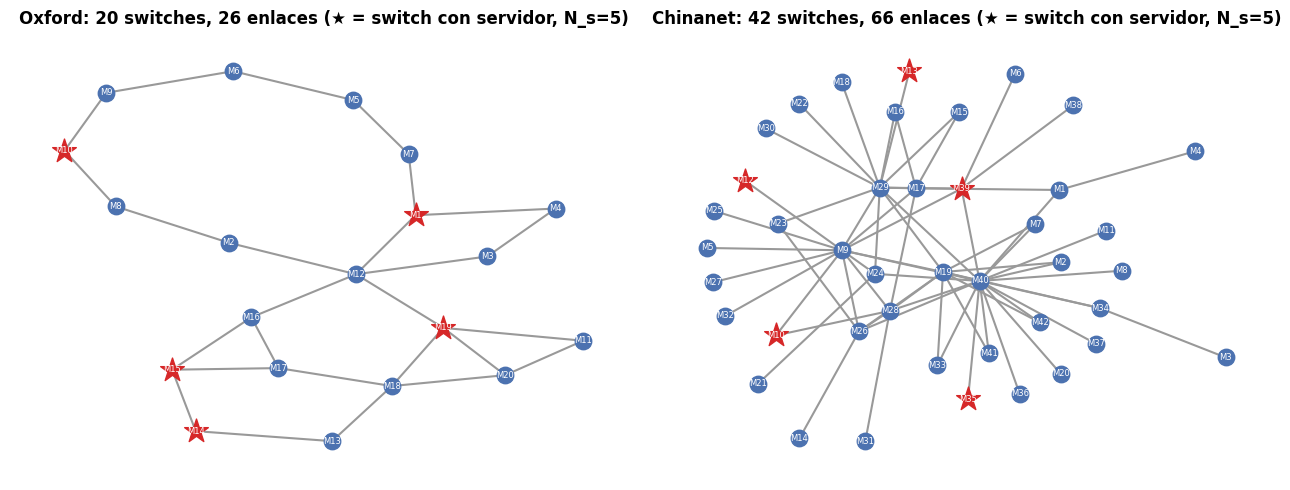

In [31]:
POS = {nombre: nx.kamada_kawai_layout(g) for nombre, g in GRAFOS.items()}


def dibujar_red(ax, red, pos, titulo, rho=None):
    """Dibuja switches (gris), servidores (estrella roja) y, opcionalmente, la utilización ρ de cada enlace."""
    Gs = red.G.subgraph(red.switches)
    if rho is None:
        nx.draw_networkx_edges(Gs, pos, ax=ax, edge_color='#999999', width=1.5)
    else:
        colores = [min(rho[red.eid[e]], 1.2) for e in Gs.edges()]
        anchos = [1 + 4 * min(rho[red.eid[e]], 1.2) for e in Gs.edges()]
        col = nx.draw_networkx_edges(Gs, pos, ax=ax, edge_color=colores, width=anchos,
                                     edge_cmap=plt.cm.RdYlGn_r, edge_vmin=0, edge_vmax=1.0)
        plt.colorbar(col, ax=ax, fraction=0.04, label='utilización ρ')
    srv_sw = {red.adj[s][0] for s in red.servidores}
    otros = [m for m in red.switches if m not in srv_sw]
    nx.draw_networkx_nodes(Gs, pos, nodelist=otros, ax=ax, node_size=140, node_color='#4c72b0')
    nx.draw_networkx_nodes(Gs, pos, nodelist=sorted(srv_sw), ax=ax, node_size=320, node_color='#d62728', node_shape='*')
    nx.draw_networkx_labels(Gs, pos, ax=ax, font_size=6, font_color='white')
    ax.set_title(titulo)
    ax.axis('off')


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, nombre in zip(axes, GRAFOS):
    red_tmp = RedSDN(GRAFOS[nombre], n_servidores=5, semilla=SEMILLA)
    dibujar_red(ax, red_tmp, POS[nombre], f'{nombre}: {len(red_tmp.switches)} switches, '
                f'{int(red_tmp.es_core.sum())} enlaces (★ = switch con servidor, N_s=5)')
plt.tight_layout()
guardar_figura(fig, 'fig_topologias')
plt.show()

## 4. Función multi-objetivo y restricciones (Ec. 1–6 y 11)

Para un individuo $\Phi^t=\{p_1,\dots,p_{N_r}\}$ se calculan, sobre el estado de red del intervalo:

1. **Ancho de banda de la ruta** (cóncava / cuello de botella, Ec. 1): $\mathcal{B}_k^t=\min_{e\in p_k} bw_e^t$, usando el ancho de banda **residual medido** $bw_e^t - bg_e^t$.
2. **Delay** (aditivo, Ec. 2): $\mathcal{D}_k^t=\sum_{e\in p_k} delay_e^{\text{ef}}$.
3. **Pérdida** (multiplicativa, Ec. 3): $\mathcal{L}_k^t = 1-\prod_{e\in p_k}(1-loss_e^{\text{ef}})$.
4. **Utilización** (Ec. 4): $\mathcal{U}^t=\min_{e\in\mathcal{E}} \rho_e$.

$$\min_{\Phi^t} f(\Phi^t)=\Big\{\tfrac{1}{N_r}\textstyle\sum_k\mathcal{D}_k^t,\ \tfrac{1}{N_r}\sum_k\mathcal{L}_k^t,\ 1-\mathcal{U}^t\Big\}\quad\text{s.a.}\quad \mathcal{B}_k^t\ge B_k\ \ (\text{Ec. 6})$$

**Decisiones de implementación (el paper no las especifica — punto crítico):**

* **Manejo de la restricción (Ec. 6):** se usa la *dominancia con restricciones* de Deb (NSGA-II): un individuo factible domina a uno infactible; entre infactibles gana el de menor violación $CV=\sum_k \max(0,B_k-\mathcal{B}_k^t)/B_k$.
* **Las Ec. 7–10 (enlaces activos, grado de visita, sin sub-ciclos)** se garantizan *por construcción*: todos los operadores producen caminos válidos del grafo y luego se aplica la eliminación de ciclos (Sub-Alg. 4).
* **Objetivo 3 (`MODO_U`)** — el paper (Ec. 4–5) y el código oficial **no coinciden**, así que se implementan varias variantes:
  * `'paper'` → $\mathcal{U}^t=\min_{e\in\mathcal{E}}\rho_e$ literal (Ec. 4). Problema: el mínimo global lo fija casi siempre un enlace periférico que ninguna ruta usa, así que $1-\mathcal{U}^t$ es **prácticamente constante** → no aporta presión selectiva (se demuestra en el Exp. 2).
  * `'codigo'` (**por defecto**) → lo que hace el código oficial (`module_individual.py`): promedio sobre las solicitudes del **cuello de botella** de cada ruta. Aquí: $1-\mathcal{U}^t=\frac{1}{N_r}\sum_k\max_{e\in p_k}\rho_e$, es decir, minimizar la utilización del enlace más cargado de cada ruta → **evita los enlaces calientes** sin premiar rutas más largas.
  * `'media'` → utilización media de la red ($1-\bar\rho$). Parece coherente con la Fig. 10, pero **premia los desvíos**: alargar rutas sube $\bar\rho$ (se compara en el Exp. 2).
  * `'activos'` → mínimo de $\rho_e$ solo sobre los enlaces usados por $\Phi^t$.

In [32]:
class Evaluador:
    """Calcula f(Φ^t) (Ec. 1-5) y la violación de la restricción de ancho de banda (Ec. 6)."""

    def __init__(self, red, solicitudes, modo_u=None):
        self.red = red
        self.modo_u = modo_u or MODELO['MODO_U']
        self.B = np.array([b for _, _, b in solicitudes])
        self.nr = len(solicitudes)
        self.residual = np.maximum(red.bw - red.bg, 0.0)     # ancho de banda disponible medido
        self.core = red.es_core
        self.ln_ok = np.log1p(-red.loss)
        self._cache = {}

    def ids(self, ruta):
        """Ruta (tupla de nodos) -> vector de índices de aristas (cacheado)."""
        c = self._cache.get(ruta)
        if c is None:
            eid = self.red.eid
            c = np.fromiter((eid[(ruta[i], ruta[i + 1])] for i in range(len(ruta) - 1)), dtype=np.int64,
                            count=len(ruta) - 1)
            self._cache[ruta] = c
        return c

    def evaluar(self, rutas, detalle=False):
        red = self.red
        ids = [self.ids(r) for r in rutas]
        largos = np.fromiter((len(x) for x in ids), dtype=np.int64, count=self.nr)
        cat = np.concatenate(ids)
        off = np.zeros(self.nr, dtype=np.int64)
        off[1:] = np.cumsum(largos)[:-1]

        carga = red.bg + np.bincount(cat, weights=np.repeat(self.B, largos), minlength=red.E)
        rho = carga / red.bw
        cola = np.where(rho < 1, rho / np.maximum(1 - rho, 1e-9), np.inf)
        d_ef = red.delay + MODELO['TAU_MS'] * np.minimum(cola, MODELO['Q_MAX'])
        desborde = np.clip(1 - 1 / np.maximum(rho, 1e-12), 0, 1)
        ln_ok = self.ln_ok + np.log(np.maximum(1 - desborde, 1e-12))

        D = np.add.reduceat(d_ef[cat], off)                      # Ec. 2
        L = 1 - np.exp(np.add.reduceat(ln_ok[cat], off))         # Ec. 3
        Bk = np.minimum.reduceat(self.residual[cat], off)        # Ec. 1
        cv = float(np.sum(np.maximum(0.0, self.B - Bk) / self.B))  # Ec. 6

        rho_c = np.minimum(rho, 1.0)
        if self.modo_u == 'codigo':                              # versión del código oficial (cuello de botella)
            U = 1.0 - np.maximum.reduceat(rho_c[cat], off).mean()
        elif self.modo_u == 'paper':                             # Ec. 4 literal
            U = rho_c[self.core].min()
        elif self.modo_u == 'activos':
            usados = np.zeros(red.E, dtype=bool)
            usados[cat] = True
            usados &= self.core
            U = rho_c[usados].min() if usados.any() else 0.0
        else:                                                    # 'media'
            U = rho_c[self.core].mean()
        F = np.array([D.mean(), L.mean(), 1.0 - U])              # Ec. 5 / 11
        if detalle:
            return F, cv, dict(D=D, L=L, Bk=Bk, rho=rho, cat=cat)
        return F, cv


def evaluar_qos(red, solicitudes, rutas):
    """Métricas de red "medidas" (Fig. 8-10) para la configuración de rutas instalada."""
    ev = Evaluador(red, solicitudes, 'media')
    F, cv, det = ev.evaluar(rutas, detalle=True)
    rho_c = det['rho'][red.es_core]
    usados = np.zeros(red.E, dtype=bool)
    usados[det['cat']] = True
    return dict(delay_ms=float(det['D'].mean()), loss_pct=100 * float(det['L'].mean()),
                util_pct=100 * float(np.minimum(rho_c, 1).mean()),
                enlaces_usados_pct=100 * float(usados[red.es_core].mean()),
                enlaces_saturados=int((rho_c >= 1).sum()),
                saltos=float(np.mean([len(r) - 3 for r in rutas])),   # saltos entre switches
                viol_bw_pct=100 * float(np.mean(det['Bk'] < ev.B)))


sol_demo = red_demo.generar_solicitudes(4, 5)
ev_demo = Evaluador(red_demo, sol_demo)
rutas_demo = [tuple(nx.shortest_path(red_demo.G, h, s)) for h, s, _ in sol_demo]
F_demo, cv_demo = ev_demo.evaluar(rutas_demo)
print('Rutas Min-Hop de ejemplo:')
for (h, s, b), r in zip(sol_demo, rutas_demo):
    print(f'  {h}->{s} (B={b:.1f} Mbps): {" -> ".join(r)}')
print(f'f(Φ) = [delay medio={F_demo[0]:.1f} ms, pérdida media={F_demo[1]:.3f}, 1-U={F_demo[2]:.3f}],  CV={cv_demo:.3f}')

Rutas Min-Hop de ejemplo:
  H8->S4 (B=2.1 Mbps): H8 -> M8 -> M10 -> S4
  H15->S1 (B=0.8 Mbps): H15 -> M15 -> S1
  H15->S2 (B=2.6 Mbps): H15 -> M15 -> M17 -> M18 -> M19 -> S2
  H4->S5 (B=1.9 Mbps): H4 -> M4 -> M1 -> M12 -> M16 -> M15 -> M14 -> S5
f(Φ) = [delay medio=145.8 ms, pérdida media=0.095, 1-U=0.164],  CV=0.000


## 5. Herramientas multi-objetivo: dominancia, *crowding*, HV e IGD

**Ordenamiento no dominado rápido (Deb et al., 2002):** divide la población en frentes $F^1, F^2,\dots$; $F^1$ son las soluciones que nadie domina. Se implementa con la **dominancia con restricciones** (ver Sección 4). Complejidad $\mathcal{O}(mN^2)$; con la unión padres+hijos ($2N$) queda $\mathcal{O}(4mN^2)$, como indica el paper.

**Distancia de aglomeración (Ec. 12):** para cada solución $i$ de un frente, ordenada por cada objetivo $j$:
$$\varphi^i=\sum_{j=1}^{3}\frac{f_j^{i+1}-f_j^{i-1}}{f_j^{\max}-f_j^{\min}},\qquad \varphi^{\text{extremos}}=\infty$$
Mide cuán "aislada" está una solución → preferir $\varphi$ grande preserva la **diversidad** del frente.

**Hipervolumen (Ec. 16):** volumen (medida de Lebesgue) del espacio dominado por el frente y acotado por el punto de referencia $r^{\text{ref}}=(1,1,1)$ en el espacio normalizado. **Mayor es mejor**; captura a la vez convergencia y diversidad. Se calcula **exactamente** en 3D por barrido en $f_3$ (rebanadas) + área 2D exacta.

**IGD (Ec. 17):** $\text{IGD}(\mathcal{F}^{\text{approx}})=\frac{1}{|\mathcal{F}^*|}\sum_{z\in\mathcal{F}^*}\min_{a\in\mathcal{F}^{\text{approx}}}\lVert z-a\rVert_2$, donde $\mathcal{F}^*$ son las soluciones no dominadas de la unión de todos los algoritmos (como en el paper). **Menor es mejor.**

**Normalización para comparar algoritmos:** en cada instancia se toma la unión de los frentes finales, se calcula el punto ideal $z^{\min}$ y nadir $z^{\max}$, y se normaliza $\tilde f=(f-z^{\min})/(1.1\,(z^{\max}-z^{\min}))$, de modo que todo queda en $[0,0.91]$ y $r^{\text{ref}}=(1,1,1)$ (margen de 10% para que los extremos aporten volumen).

In [33]:
def ordenamiento_no_dominado(F, cv=None):
    """Fast non-dominated sorting con dominancia con restricciones. Devuelve lista de frentes (arrays de índices)."""
    F = np.asarray(F, dtype=float)
    n = len(F)
    cv = np.zeros(n) if cv is None else np.asarray(cv, dtype=float)
    pareto = np.all(F[:, None, :] <= F[None, :, :], axis=2) & np.any(F[:, None, :] < F[None, :, :], axis=2)
    fa = cv <= 0
    D = ((fa[:, None] & ~fa[None, :])                                   # factible domina a infactible
         | (~fa[:, None] & ~fa[None, :] & (cv[:, None] < cv[None, :]))  # menor violación domina
         | (fa[:, None] & fa[None, :] & pareto))                        # dominancia de Pareto
    n_dom = D.sum(axis=0)              # cuántos dominan a cada individuo
    asignado = np.zeros(n, dtype=bool)
    frentes = []
    actual = np.flatnonzero(n_dom == 0)
    while len(actual):
        frentes.append(actual)
        asignado[actual] = True
        n_dom = n_dom - D[actual].sum(axis=0)
        actual = np.flatnonzero((n_dom == 0) & ~asignado)
    return frentes


def distancia_aglomeracion(F):
    """Crowding distance (Ec. 12)."""
    F = np.asarray(F, dtype=float)
    n, m = F.shape
    d = np.zeros(n)
    if n <= 2:
        d[:] = np.inf
        return d
    for j in range(m):
        o = np.argsort(F[:, j], kind='stable')
        fmin, fmax = F[o[0], j], F[o[-1], j]
        d[o[0]] = d[o[-1]] = np.inf
        if fmax > fmin:
            d[o[1:-1]] += (F[o[2:], j] - F[o[:-2], j]) / (fmax - fmin)
    return d


def no_dominados(F):
    F = np.unique(np.asarray(F, dtype=float), axis=0)
    return F[ordenamiento_no_dominado(F)[0]]


def hipervolumen(F, ref=(1.0, 1.0, 1.0)):
    """Hipervolumen exacto 3D (minimización) por barrido en f3 + área 2D exacta (Ec. 16)."""
    F = np.asarray(F, dtype=float)
    ref = np.asarray(ref, dtype=float)
    F = F[np.all(F < ref, axis=1)]
    if len(F) == 0:
        return 0.0
    F = no_dominados(F)
    F = F[np.argsort(F[:, 2])]
    vol = 0.0
    for i in range(len(F)):
        z_sig = F[i + 1, 2] if i + 1 < len(F) else ref[2]
        h = z_sig - F[i, 2]
        if h <= 0:
            continue
        S = F[:i + 1, :2]
        o = np.argsort(S[:, 0])
        x = S[o, 0]
        y = np.minimum.accumulate(S[o, 1])
        x_sig = np.append(x[1:], ref[0])
        vol += h * np.sum((x_sig - x) * (ref[1] - y))
    return float(vol)


def igd(F_ref, F_aprox):
    """Inverted Generational Distance (Ec. 17)."""
    F_ref, F_aprox = np.asarray(F_ref, float), np.asarray(F_aprox, float)
    d = np.sqrt(((F_ref[:, None, :] - F_aprox[None, :, :]) ** 2).sum(axis=2)).min(axis=1)
    return float(d.mean())


def metricas_conjuntas(frentes):
    """frentes: {algoritmo: array (k x 3)} de la MISMA instancia -> {algoritmo: (HV, IGD)} normalizados en conjunto."""
    U = np.vstack(list(frentes.values()))
    ideal, nadir = U.min(axis=0), U.max(axis=0)
    rango = np.where(nadir - ideal > 1e-12, nadir - ideal, 1.0)
    norm = lambda A: (np.asarray(A) - ideal) / (1.1 * rango)
    F_star = no_dominados(norm(U))
    return {k: (hipervolumen(norm(A)), igd(F_star, norm(A))) for k, A in frentes.items()}

**Validación de las implementaciones** (buena práctica y respuesta lista si la comisión pregunta "¿cómo sabes que tu HV está bien?"): se compara el HV exacto con una estimación Monte Carlo independiente, y se verifica la dominancia en un ejemplo pequeño. Si tienes `pymoo` instalado, también se contrasta con `pymoo.indicators.hv.HV`.

In [34]:
rng_val = np.random.default_rng(0)
P_val = rng_val.random((30, 3)) * 0.9
P_val = no_dominados(P_val)
hv_exacto = hipervolumen(P_val)
muestras = rng_val.random((400_000, 3))
dominadas = np.zeros(len(muestras), dtype=bool)
for p in P_val:
    dominadas |= np.all(muestras >= p, axis=1)
print(f'HV exacto = {hv_exacto:.4f} | HV Monte Carlo (400k muestras) = {dominadas.mean():.4f}')
assert abs(hv_exacto - dominadas.mean()) < 0.01, 'El hipervolumen no coincide con Monte Carlo'

F_toy = np.array([[1, 2, 3], [2, 1, 3], [2, 2, 4], [3, 3, 5]])
print('Frentes del ejemplo [[1,2,3],[2,1,3],[2,2,4],[3,3,5]]:', [list(f) for f in ordenamiento_no_dominado(F_toy)])
print('Crowding del primer frente:', distancia_aglomeracion(F_toy[:2]))

try:
    from pymoo.indicators.hv import HV as HV_pymoo
    print(f'HV pymoo = {HV_pymoo(ref_point=np.ones(3))(P_val):.4f}')
except ImportError:
    print('(pymoo no instalado: se omite el contraste opcional)')

HV exacto = 0.6378 | HV Monte Carlo (400k muestras) = 0.6373
Frentes del ejemplo [[1,2,3],[2,1,3],[2,2,4],[3,3,5]]: [[np.int64(0), np.int64(1)], [np.int64(2)], [np.int64(3)]]
Crowding del primer frente: [inf inf]
(pymoo no instalado: se omite el contraste opcional)


## 6. GAMR: implementación de los 6 sub-algoritmos

**Representación cromosómica (Fig. 3):** un individuo es una solución completa $\Phi^t$ con exactamente $N_r$ **segmentos génicos de largo variable**; el segmento $k$ es la secuencia de nodos de la ruta $p_k=(H_i\to M_{m_1}\to\dots\to S_j)$.

```
individuo = [ (H3, M3, M7, M12, S1),        <- ruta de la solicitud R_1
              (H9, M9, M4, S2),             <- ruta de la solicitud R_2
              ...                                                   
              (H17, M17, M5, M7, M12, S1) ] <- ruta de la solicitud R_Nr
```

Primero se implementan los operadores como **funciones puras** (fáciles de explicar y probar); luego la clase `GAMR` los orquesta en el ciclo evolutivo (Fig. 2, Fase 3).

### 6.1 Sub-Alg. 4 — Eliminación de ciclos
Al cruzar o mutar caminos pueden repetirse switches (bucles de enrutamiento que violan las Ec. 8–10). Para cada nodo $\lambda$ con primera aparición $i$ y última $j$, si $i\neq j$ se elimina el sub-segmento $(i+1,\dots,j)$. Implementación en una sola pasada $\mathcal{O}(|p|)$: al reencontrar un nodo ya visitado se "rebobina" la ruta hasta su primera aparición.

In [35]:
def eliminar_ciclos(ruta):
    """Sub-Alg. 4: elimina todo sub-camino entre dos apariciones del mismo nodo."""
    salida, pos = [], {}
    for v in ruta:
        if v in pos:
            k = pos[v]
            for w in salida[k + 1:]:
                del pos[w]
            del salida[k + 1:]
        else:
            pos[v] = len(salida)
            salida.append(v)
    return tuple(salida)


ejemplo = ('H1', 'M1', 'M2', 'M3', 'M4', 'M2', 'M5', 'S1')
print('Antes  :', ' -> '.join(ejemplo))
print('Después:', ' -> '.join(eliminar_ciclos(ejemplo)), '  (se eliminó el bucle M2-M3-M4-M2)')

Antes  : H1 -> M1 -> M2 -> M3 -> M4 -> M2 -> M5 -> S1
Después: H1 -> M1 -> M2 -> M5 -> S1   (se eliminó el bucle M2-M3-M4-M2)


### 6.2 Sub-Alg. 1 — Inicialización híbrida (RSBI + PSBI) y Sub-Alg. 6 — Memoria PRSM

Para cada solicitud $R_k=(H_i,S_j,B_k)$ de cada individuo se sortea $u\sim\mathcal{U}[0,1]$:

* **PSBI (explotación)** si $u\le\alpha$ **y** existe en la memoria $\mathcal{M}$ una ruta previa hacia $S_j$: se toma esa ruta, se elige un switch $\lambda$ al azar dentro de ella, se calcula el camino más corto en saltos (**BFS**) $q_k: H_i\to\lambda$ y se concatena $q_k\cup p_k[\lambda\to S_j]$; luego se eliminan ciclos.
* **RSBI (exploración)** en otro caso: desde $H_i$ se avanza a un switch vecino **no visitado** elegido al azar hasta llegar a $S_j$, retrocediendo (*backtracking*) en callejones sin salida (DFS aleatorizado).

**PRSM (Sub-Alg. 6):** $\mathcal{M}$ guarda **a lo sumo una ruta por servidor** ($|\mathcal{M}|\le N_s$). Tras cada instancia se **reemplaza** la ruta de cada servidor por la de la solución elegida. Con $\alpha=0$ (o sin memoria) GAMR degenera en un NSGA-II con inicialización aleatoria, que es el *baseline* del Exp. 3.

In [36]:
def rsbi(red, h, s, rnd):
    """RSBI: camino aleatorio sin revisitas desde h hasta s, con backtracking (DFS aleatorizado)."""
    ruta, visitados = [h], {h}
    while ruta[-1] != s:
        u = ruta[-1]
        candidatos = [v for v in red.adj[u] if v not in visitados and (v == s or red.tipo[v] == 'switch')]
        if candidatos:
            v = rnd.choice(candidatos)
            ruta.append(v)
            visitados.add(v)
        else:
            ruta.pop()                      # callejón sin salida -> retroceder
            if not ruta:
                raise RuntimeError(f'No existe camino {h}->{s}')
    return tuple(ruta)


def bfs_predecesores(red, origen):
    """Árbol BFS (camino más corto en saltos) desde un host, avanzando solo por switches."""
    pred, cola = {origen: None}, deque([origen])
    while cola:
        u = cola.popleft()
        for v in red.adj[u]:
            if v not in pred and red.tipo[v] == 'switch':
                pred[v] = u
                cola.append(v)
    return pred


def psbi(ruta_memoria, h, camino_bfs, rnd):
    """PSBI: reutiliza una ruta previa hacia el mismo servidor, conectando el nuevo host por BFS."""
    i = rnd.randrange(1, len(ruta_memoria) - 1)        # switch λ elegido al azar dentro de p_k ∈ M
    q = camino_bfs(h, ruta_memoria[i])                 # H_i -> ... -> λ (BFS)
    return eliminar_ciclos(tuple(q) + tuple(ruta_memoria[i + 1:]))


rnd_demo = random.Random(1)
h0, s0, _ = sol_demo[0]
r_rsbi = rsbi(red_demo, h0, s0, rnd_demo)
print(f'RSBI {h0}->{s0}:', ' -> '.join(r_rsbi), f'({len(r_rsbi) - 3} saltos; Min-Hop: {len(rutas_demo[0]) - 3})')
_pred = {}
def _camino_bfs(h, destino):
    p = _pred.setdefault(h, bfs_predecesores(red_demo, h))
    c = [destino]
    while c[-1] != h:
        c.append(p[c[-1]])
    return c[::-1]
otro_host = next(x for x in red_demo.hosts if x != h0)
r_psbi = psbi(r_rsbi, otro_host, _camino_bfs, rnd_demo)
print(f'PSBI {otro_host}->{s0} reutilizando la ruta anterior como memoria:', ' -> '.join(r_psbi))

RSBI H8->S4: H8 -> M8 -> M10 -> S4 (1 saltos; Min-Hop: 1)
PSBI H1->S4 reutilizando la ruta anterior como memoria: H1 -> M1 -> M12 -> M2 -> M8 -> M10 -> S4


### 6.3 Sub-Alg. 2 — Cruzamiento multi-punto en grafos (Fig. 4) y Sub-Alg. 3 — Mutación por inserción (Fig. 5)

**Cruzamiento:** se opera segmento a segmento ($k=1..N_r$). Para las rutas $p_1,p_2$ de la misma solicitud se calcula el conjunto de nodos comunes $\Omega$ (sin extremos). Si $\Omega\neq\emptyset$ y $u\le p_c$, se elige $\lambda\in\Omega$ y se **intercambian las colas** después de $\lambda$. Como ambos padres pasan por $\lambda$, los hijos son **caminos válidos del grafo por construcción** (a diferencia del cruce de un punto clásico sobre vectores). "Multi-punto" = un punto de cruce independiente por cada uno de los $N_r$ segmentos.

**Mutación:** en cada ruta se eligen dos nodos consecutivos $\lambda_1,\lambda_2$; $\gamma$ = switches adyacentes a ambos. Si $\gamma\neq\emptyset$ y $u\le p_m$, se inserta $\tilde\lambda\in\gamma$ entre ellos ($\lambda_1\to\tilde\lambda\to\lambda_2$ es válido porque $\tilde\lambda$ es vecino de ambos) y se eliminan ciclos.

In [37]:
def cruce_multipunto(p1, p2, pc, rnd):
    """Sub-Alg. 2 sobre UN segmento génico: intercambia las colas en un nodo común λ ∈ Ω."""
    en_p2 = set(p2[1:-1])
    omega = [v for v in p1[1:-1] if v in en_p2]        # lista ordenada -> reproducible
    if omega and rnd.random() <= pc:
        lam = rnd.choice(omega)
        i, j = p1.index(lam), p2.index(lam)
        return eliminar_ciclos(p1[:i] + p2[j:]), eliminar_ciclos(p2[:j] + p1[i:])
    return p1, p2


def mutacion_insercion(p, vecinos_comunes, pm, rnd):
    """Sub-Alg. 3: inserta un switch adyacente a dos nodos consecutivos λ1, λ2."""
    i = rnd.randrange(len(p) - 1)
    gamma = vecinos_comunes[(p[i], p[i + 1])]
    if gamma and rnd.random() <= pm:
        nuevo = rnd.choice(gamma)
        return eliminar_ciclos(p[:i + 1] + (nuevo,) + p[i + 1:])
    return p


rnd_demo = random.Random(7)
pa, pb = rsbi(red_demo, h0, s0, rnd_demo), rsbi(red_demo, h0, s0, rnd_demo)
ca, cb = cruce_multipunto(pa, pb, 1.0, rnd_demo)
print('Padre 1:', ' -> '.join(pa)); print('Padre 2:', ' -> '.join(pb))
print('Hijo 1 :', ' -> '.join(ca)); print('Hijo 2 :', ' -> '.join(cb))
# Mutación forzada (p_m=1) sobre un tramo switch-switch que pertenece a un triángulo, para ilustrar
arista_tri = next(((u, v) for (u, v), c in red_demo.vecinos_comunes.items()
                   if c and red_demo.tipo[u] == red_demo.tipo[v] == 'switch'), None)
if arista_tri:
    print('Mutación del tramo', ' -> '.join(arista_tri), ' ==> ',
          ' -> '.join(mutacion_insercion(arista_tri, red_demo.vecinos_comunes, 1.0, rnd_demo)))
n_tri = sum(1 for (u, v), c in red_demo.vecinos_comunes.items() if c) // 2
print(f'Enlaces de Oxford donde la mutación es posible (γ≠∅): {n_tri} de {int(red_demo.es_core.sum())}')

Padre 1: H8 -> M8 -> M10 -> S4
Padre 2: H8 -> M8 -> M10 -> S4
Hijo 1 : H8 -> M8 -> M10 -> S4
Hijo 2 : H8 -> M8 -> M10 -> S4
Mutación del tramo M11 -> M19  ==>  M11 -> M20 -> M19
Enlaces de Oxford donde la mutación es posible (γ≠∅): 8 de 26


### 6.4 Ciclo completo de GAMR (Fig. 2, Fase 3): selección, parada temprana, elección final y memoria

**Sub-Alg. 5 — Selección de supervivientes (NSGA-II elitista):** $Q_G=P_G\cup O_G$ ($2N$ individuos) → frentes no dominados $F^1,F^2,\dots$ → se agregan frentes completos mientras quepan; el frente límite se completa con los individuos de **mayor** $\varphi^i$ (Ec. 12). Los padres se eligen por **torneo binario** (gana menor rango; si empatan, mayor *crowding*).

**Parada temprana (Ec. 13):**
$$\epsilon(G)=\begin{cases}(G^{\max}-G)\cdot\big(HV_G-HV_{G-G^{pre}}\big), & G\ge G^{pre}\\ 1 & \text{en otro caso}\end{cases}\qquad\text{se detiene cuando }\epsilon(G)=0$$
es decir, cuando el HV del primer frente no mejora en $G^{pre}=10$ generaciones **o** se llega a $G^{\max}$. ($HV_G$ se calcula con una escala fija por corrida.)

**Elección de la solución a instalar (Fase 3.7):** de todo el frente de Pareto final, el controlador instala la solución con **menor solapamiento de enlaces** $\sum_e\max(0,\#\text{flujos}_e-1)$ (empates → menor delay). El resto del frente queda como **respaldo** ante caídas de enlaces.

**Complejidad (Sec. IV-C):** $\mathcal{O}\big(G^{\max}(N N_r|\mathcal{V}|^2+|\mathcal{E}|+4mN^2)\big)$ con $m=3$.

In [38]:
class Individuo:
    __slots__ = ('rutas', 'F', 'cv', 'rango', 'crowd')

    def __init__(self, rutas, F, cv):
        self.rutas, self.F, self.cv = rutas, F, cv
        self.rango, self.crowd = 0, 0.0


class GAMR:
    """GAMR (usar_memoria=True, α=0.5) o NSGA-II estándar (usar_memoria=False -> α=0, sin PRSM)."""

    def __init__(self, red, params=None, usar_memoria=True, alpha=None, semilla=0, modo_u=None, nombre=None):
        self.red = red
        self.p = dict(PARAM_GAMR if params is None else params)
        self.usar_memoria = usar_memoria
        self.alpha = (self.p['ALPHA'] if alpha is None else alpha) if usar_memoria else 0.0
        self.rnd = random.Random(semilla)
        self.modo_u = modo_u or MODELO['MODO_U']
        self.nombre = nombre or ('GAMR' if usar_memoria else 'NSGA-II')
        self.memoria = {}          # PRSM: servidor S_j -> ruta óptima previa
        self._pred_bfs = {}

    # ---------- utilidades ----------
    def _camino_bfs(self, h, destino):
        pred = self._pred_bfs.get(h)
        if pred is None:
            pred = self._pred_bfs[h] = bfs_predecesores(self.red, h)
        camino = [destino]
        while camino[-1] != h:
            camino.append(pred[camino[-1]])
        return camino[::-1]

    def _nuevo(self, rutas, ev):
        F, cv = ev.evaluar(rutas)
        return Individuo(rutas, F, cv)

    # ---------- Sub-Alg. 1: inicialización híbrida ----------
    def inicializar_poblacion(self, solicitudes, ev):
        P = []
        for _ in range(self.p['N']):
            rutas = []
            for h, s, _b in solicitudes:
                if self.rnd.random() <= self.alpha and s in self.memoria:
                    rutas.append(psbi(self.memoria[s], h, self._camino_bfs, self.rnd))   # explotación
                else:
                    rutas.append(rsbi(self.red, h, s, self.rnd))                         # exploración
            P.append(self._nuevo(rutas, ev))
        return P

    # ---------- selección de padres (torneo) ----------
    def _torneo(self, P):
        mejor = P[self.rnd.randrange(len(P))]
        for _ in range(self.p['TORNEO'] - 1):
            otro = P[self.rnd.randrange(len(P))]
            if otro.rango < mejor.rango or (otro.rango == mejor.rango and otro.crowd > mejor.crowd):
                mejor = otro
        return mejor

    # ---------- Sub-Alg. 2 + 3 + 4: descendencia ----------
    def generar_descendencia(self, P, ev):
        pc, pm, vc, rnd = self.p['PC'], self.p['PM'], self.red.vecinos_comunes, self.rnd
        O = []
        while len(O) < self.p['N']:
            a, b = self._torneo(P), self._torneo(P)
            h1, h2 = [], []
            for p1, p2 in zip(a.rutas, b.rutas):
                c1, c2 = cruce_multipunto(p1, p2, pc, rnd)
                h1.append(mutacion_insercion(c1, vc, pm, rnd))
                h2.append(mutacion_insercion(c2, vc, pm, rnd))
            O.append(self._nuevo(h1, ev))
            O.append(self._nuevo(h2, ev))
        return O[:self.p['N']]

    # ---------- Sub-Alg. 5: selección elitista NSGA-II ----------
    def seleccionar(self, Q, N):
        F = np.array([q.F for q in Q])
        cv = np.array([q.cv for q in Q])
        elegidos = []
        for r, frente in enumerate(ordenamiento_no_dominado(F, cv)):
            cd = distancia_aglomeracion(F[frente])
            for idx, d in zip(frente, cd):
                Q[idx].rango, Q[idx].crowd = r, d
            if len(elegidos) + len(frente) <= N:
                elegidos.extend(frente)
            else:
                orden = np.argsort(-cd, kind='stable')
                elegidos.extend(frente[orden[:N - len(elegidos)]])
                break
        return [Q[i] for i in elegidos]

    # ---------- Ec. 13: parada temprana ----------
    def _hv_poblacion(self, P, escala):
        frente = [q for q in P if q.rango == 0]
        factibles = [q for q in frente if q.cv <= 0]
        F = np.array([q.F for q in (factibles or frente)]) / escala
        return hipervolumen(F)

    def epsilon(self, G, hv_hist):
        if G < self.p['G_PRE']:
            return 1.0
        delta = hv_hist[G] - hv_hist[G - self.p['G_PRE']]
        if abs(delta) < self.p['TOL_HV']:
            delta = 0.0
        return (self.p['G_MAX'] - G) * delta

    # ---------- Fase 3.7: solución con menor solapamiento de enlaces ----------
    def menor_solapamiento(self, frente, ev):
        candidatos = [q for q in frente if q.cv <= 0] or frente
        mejor, clave_mejor = None, None
        for q in candidatos:
            cat = np.concatenate([ev.ids(r) for r in q.rutas])
            cat = cat[self.red.es_core[cat]]
            solap = int(np.maximum(np.bincount(cat, minlength=self.red.E) - 1, 0).sum())
            clave = (solap, q.F[0])
            if clave_mejor is None or clave < clave_mejor:
                mejor, clave_mejor = q, clave
        return mejor, clave_mejor[0]

    # ---------- Sub-Alg. 6: memoria PRSM ----------
    def actualizar_memoria(self, solicitudes, rutas):
        for (_h, s, _b), r in zip(solicitudes, rutas):
            self.memoria[s] = r            # "Replace p in M by p'": 1 ruta por servidor

    # ---------- ciclo principal ----------
    def resolver(self, solicitudes, escala=None):
        t0 = time.perf_counter()
        ev = Evaluador(self.red, solicitudes, self.modo_u)
        N, G_MAX = self.p['N'], self.p['G_MAX']
        uso_memoria = self.alpha > 0 and any(s in self.memoria for _, s, _ in solicitudes)

        P = self.seleccionar(self.inicializar_poblacion(solicitudes, ev), N)
        if escala is None:
            escala = np.array([1.1 * max(q.F[0] for q in P), 1.0, 1.0])   # escala fija de HV_G para esta corrida
        hv_hist = [self._hv_poblacion(P, escala)]
        G = 0
        for G in range(1, G_MAX + 1):
            O = self.generar_descendencia(P, ev)
            P = self.seleccionar(P + O, N)
            hv_hist.append(self._hv_poblacion(P, escala))
            if self.epsilon(G, hv_hist) == 0:
                break

        frente = [q for q in P if q.rango == 0]
        elegida, solap = self.menor_solapamiento(frente, ev)
        tiempo = time.perf_counter() - t0
        if self.usar_memoria:
            self.actualizar_memoria(solicitudes, elegida.rutas)
        factibles = [q for q in frente if q.cv <= 0]
        return dict(nombre=self.nombre, rutas=elegida.rutas, F=elegida.F, cv=elegida.cv, solapamiento=solap,
                    frente=np.unique(np.array([q.F for q in (factibles or frente)]), axis=0),
                    poblacion=P, generaciones=G, tiempo=tiempo, hv_hist=np.array(hv_hist), escala=escala,
                    uso_memoria=uso_memoria, frac_factible=np.mean([q.cv <= 0 for q in P]))

## 7. Algoritmos de referencia para las métricas de red (Fig. 8–11)

* **MH — Min-Hop:** camino más corto en número de saltos (BFS) para cada solicitud, **independiente** del estado de la red. Es el enrutamiento mono-objetivo clásico (tipo Dijkstra con pesos unitarios) que concentra el tráfico.
* **LCP-WAC\* (proxy):** el LCP-WAC original (Hoang et al., 2023, mismo grupo de investigación) usa una **LSTM** para *predecir* el costo de cada enlace (utilización, pérdida, delay) y enruta con un **costo ponderado** (suma escalarizada, mono-objetivo). Aquí **no se entrena una LSTM**; se conserva su esencia:
  1. el costo de cada enlace se calcula a partir de una **predicción basada en el historial** (media móvil exponencial de los intervalos anteriores, no del estado actual);
  2. costo ponderado $c_e=\tfrac13\hat\rho_e+\tfrac13\,loss_e/0.1+\tfrac13\,delay_e/100$;
  3. enrutamiento secuencial con Dijkstra, actualizando la carga prevista tras cada solicitud (*workload-aware*).

  El asterisco indica que es una **aproximación**. Captura el mecanismo que el paper señala como debilidad de los modelos predictivos: cuando la red cambia bruscamente (β alto), **la predicción histórica deja de representar el estado real**.

In [39]:
class MinHop:
    nombre = 'MH'

    def __init__(self, red):
        self.red, self._cache = red, {}

    def resolver(self, solicitudes):
        t0 = time.perf_counter()
        rutas = []
        for h, s, _b in solicitudes:
            if (h, s) not in self._cache:
                self._cache[(h, s)] = tuple(nx.shortest_path(self.red.G, h, s))
            rutas.append(self._cache[(h, s)])
        return dict(nombre=self.nombre, rutas=rutas, tiempo=time.perf_counter() - t0)


class LCPWACProxy:
    nombre = 'LCP-WAC*'

    def __init__(self, red, pesos=(1 / 3, 1 / 3, 1 / 3), suavizado=0.5):
        self.red, self.pesos, self.a = red, pesos, suavizado

    def _prediccion(self):
        """Predicción del estado (bw, carga de fondo) a partir de los intervalos ANTERIORES (EWMA)."""
        hist = self.red.historial
        pasado = hist[:-1] if len(hist) > 1 else hist[-1:]     # arranque en frío: usa la 1ª medición
        bw_hat, bg_hat = pasado[0][0].copy(), pasado[0][1].copy()
        for bw, bg in pasado[1:]:
            bw_hat = self.a * bw + (1 - self.a) * bw_hat
            bg_hat = self.a * bg + (1 - self.a) * bg_hat
        return bw_hat, bg_hat

    def resolver(self, solicitudes):
        t0 = time.perf_counter()
        red, (w1, w2, w3) = self.red, self.pesos
        bw_hat, carga = self._prediccion()
        base = w2 * red.loss / 0.10 + w3 * red.delay / 100.0
        rutas = []
        for h, s, b in solicitudes:
            costo = w1 * np.minimum((carga + b) / bw_hat, 2.0) + base + 1e-3
            costo[~red.es_core] = 1e-3
            ruta = tuple(nx.dijkstra_path(red.G, h, s, weight=lambda u, v, d: costo[red.eid[(u, v)]]))
            for i in range(len(ruta) - 1):
                carga[red.eid[(ruta[i], ruta[i + 1])]] += b
            rutas.append(ruta)
        return dict(nombre=self.nombre, rutas=rutas, tiempo=time.perf_counter() - t0)

## 8. Experimento 1 — Instancia de demostración (Oxford, $N_r=20$, $N_s=5$)

Se simulan **dos intervalos consecutivos** $\Delta^1,\Delta^2$: en $\Delta^1$ la memoria PRSM está vacía (GAMR ≡ NSGA-II); en $\Delta^2$ GAMR ya puede **reutilizar las rutas óptimas previas** (PSBI). Se muestran:

1. El **frente de Pareto 3D** final de GAMR y NSGA-II + la solución instalada (menor solapamiento).
2. La **convergencia de $HV_G$** por generación y el punto donde actúa la **parada temprana (Ec. 13)**.
3. La **memoria PRSM** resultante (1 ruta por servidor).

👉 Usar en diapositivas **6–8** (inicialización/memoria, operadores, selección y parada).

In [40]:
red_e1 = RedSDN(GRAFOS['Oxford'], n_servidores=5, semilla=SEMILLA)
gamr_e1 = GAMR(red_e1, usar_memoria=True, semilla=SEMILLA)
nsga_e1 = GAMR(red_e1, usar_memoria=False, semilla=SEMILLA + 1)

# Intervalo Δ^1: memoria vacía
sol_e1 = red_e1.generar_solicitudes(20, 5)
r_n1 = nsga_e1.resolver(sol_e1)
r_g1 = gamr_e1.resolver(sol_e1, escala=r_n1['escala'])

# Intervalo Δ^2: la red cambia (Ec. 14) y llegan nuevas solicitudes; GAMR usa su memoria
red_e1.nuevo_intervalo()
sol_e1 = red_e1.generar_solicitudes(20, 5)
r_n2 = nsga_e1.resolver(sol_e1)
r_g2 = gamr_e1.resolver(sol_e1, escala=r_n2['escala'])

filas = []
for t, (rg, rn) in enumerate([(r_g1, r_n1), (r_g2, r_n2)], start=1):
    m = metricas_conjuntas({'GAMR': rg['frente'], 'NSGA-II': rn['frente']})
    for r in (rg, rn):
        filas.append(dict(intervalo=t, algoritmo=r['nombre'], memoria_usada=r['uso_memoria'],
                          generaciones=r['generaciones'], tiempo_s=r['tiempo'], tamano_frente=len(r['frente']),
                          HV=m[r['nombre']][0], IGD=m[r['nombre']][1], delay_ms=r['F'][0],
                          loss_pct=100 * r['F'][1], f3=r['F'][2], solapamiento=r['solapamiento']))
tabla_e1 = pd.DataFrame(filas).set_index(['intervalo', 'algoritmo'])
guardar_tabla(tabla_e1, 'exp1_instancia_demo')
display(tabla_e1.round(3))

print('Memoria PRSM de GAMR tras Δ^2 (una ruta por servidor):')
for s, r in sorted(gamr_e1.memoria.items()):
    print(f'  {s}: {" -> ".join(r)}')

memoria_usada  generaciones  tiempo_s  tamano_frente  \
intervalo algoritmo                                                         
1         GAMR               False            30     0.745             78   
          NSGA-II            False            30     0.890             76   
2         GAMR                True            35     0.943             82   
          NSGA-II            False            43     1.050             88   

                        HV    IGD  delay_ms  loss_pct     f3  solapamiento  
intervalo algoritmo                                                         
1         GAMR       0.687  0.003   203.384    15.857  0.276            45  
          NSGA-II    0.684  0.005   203.384    15.857  0.276            45  
2         GAMR       0.706  0.043   198.662    15.898  0.245            44  
          NSGA-II    0.721  0.051   198.662    15.898  0.245            44

Memoria PRSM de GAMR tras Δ^2 (una ruta por servidor):
  S1: H17 -> M17 -> M15 -> S1
  S2: H6 -> M6 -> M5 -> M7 -> M1 -> M12 -> M19 -> S2
  S3: H16 -> M16 -> M12 -> M1 -> S3
  S4: H11 -> M11 -> M19 -> M12 -> M2 -> M8 -> M10 -> S4
  S5: H15 -> M15 -> M14 -> S5


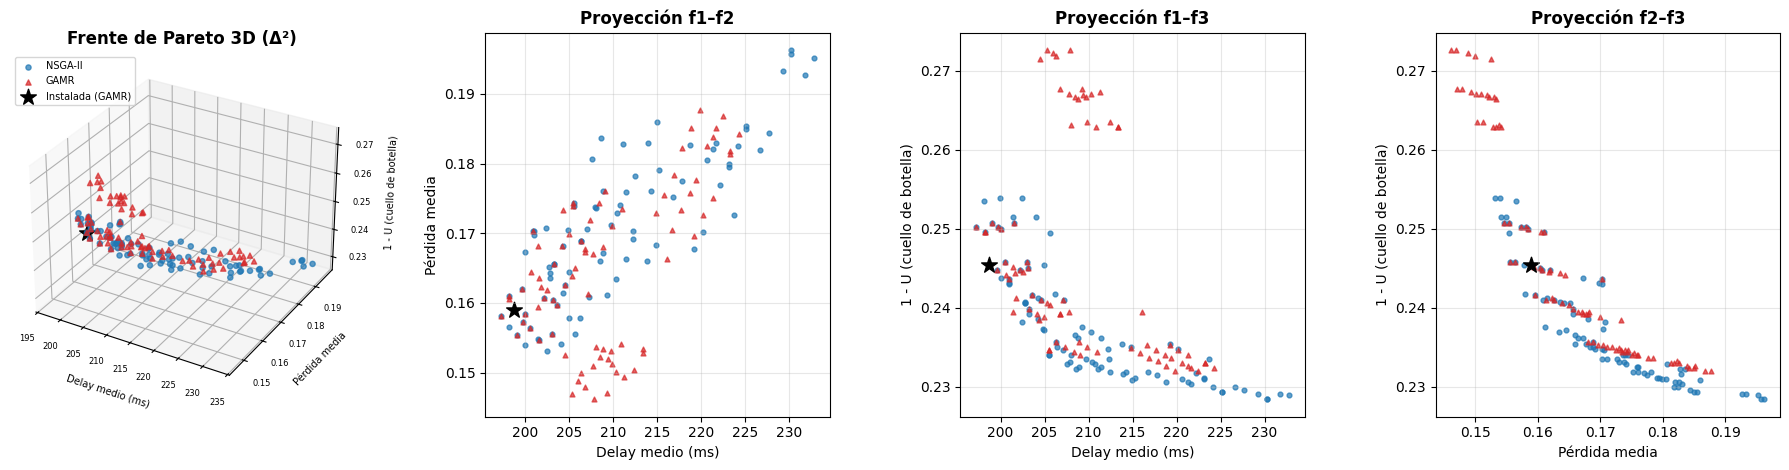

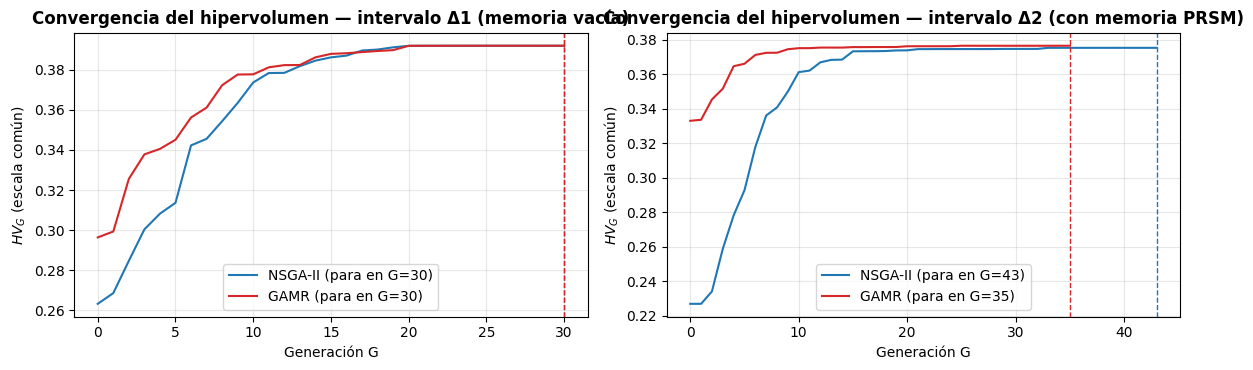

In [41]:
fig = plt.figure(figsize=(18, 4.8))
ax3d = fig.add_subplot(1, 4, 1, projection='3d')
etiquetas = ['Delay medio (ms)', 'Pérdida media', '1 - U (cuello de botella)']
for r, marcador in ((r_n2, 'o'), (r_g2, '^')):
    F = r['frente']
    ax3d.scatter(F[:, 0], F[:, 1], F[:, 2], s=14, marker=marcador, color=COLORES[r['nombre']], alpha=0.7, label=r['nombre'])
ax3d.scatter(*r_g2['F'], s=140, marker='*', color='k', label='Instalada (GAMR)')
ax3d.set_xlabel(etiquetas[0], fontsize=7); ax3d.set_ylabel(etiquetas[1], fontsize=7); ax3d.set_zlabel(etiquetas[2], fontsize=7)
ax3d.tick_params(labelsize=6)
ax3d.set_title('Frente de Pareto 3D (Δ²)')
ax3d.legend(fontsize=7, loc='upper left')
for k, (i, j) in enumerate([(0, 1), (0, 2), (1, 2)], start=2):
    ax = fig.add_subplot(1, 4, k)
    for r, marcador in ((r_n2, 'o'), (r_g2, '^')):
        ax.scatter(r['frente'][:, i], r['frente'][:, j], s=12, marker=marcador, color=COLORES[r['nombre']], alpha=0.7, label=r['nombre'])
    ax.scatter(r_g2['F'][i], r_g2['F'][j], s=140, marker='*', color='k')
    ax.set_xlabel(etiquetas[i]); ax.set_ylabel(etiquetas[j])
    ax.set_title(f'Proyección f{i + 1}–f{j + 1}')
plt.tight_layout()
fig.subplots_adjust(wspace=0.38)
guardar_figura(fig, 'fig_exp1_frente_pareto')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (rg, rn, t) in zip(axes, [(r_g1, r_n1, 1), (r_g2, r_n2, 2)]):
    for r in (rn, rg):
        ax.plot(r['hv_hist'], color=COLORES[r['nombre']], label=f"{r['nombre']} (para en G={r['generaciones']})")
        ax.axvline(r['generaciones'], color=COLORES[r['nombre']], ls='--', lw=1)
    ax.set_xlabel('Generación G'); ax.set_ylabel('$HV_G$ (escala común)')
    ax.set_title(f'Convergencia del hipervolumen — intervalo Δ{t}' + (' (memoria vacía)' if t == 1 else ' (con memoria PRSM)'))
    ax.legend()
plt.tight_layout()
guardar_figura(fig, 'fig_exp1_convergencia_hv')
plt.show()

**Cómo interpretar:**
* En $\Delta^1$ ambos algoritmos son equivalentes (misma inicialización aleatoria): las curvas deben ser parecidas.
* En $\Delta^2$ la curva de GAMR suele **partir más arriba** (la población inicial ya contiene rutas buenas gracias a PSBI) y **estabilizarse antes**, por lo que la Ec. 13 la detiene en menos generaciones → **menor tiempo de cómputo**, que es el argumento central del paper para hacer viable un AG en el plano de control.
* La línea discontinua marca la generación donde $\epsilon(G)=0$.
* Es normal que GAMR y NSGA-II **instalen la misma solución**: el criterio de *menor solapamiento* elige un extremo del frente que ambos suelen encontrar. La ventaja de la memoria está en **cuánto cuesta llegar** (generaciones/tiempo), no necesariamente en la solución final.
* Si en tu corrida GAMR no para antes, coméntalo: el beneficio de la memoria depende de cuánto cambió la red entre intervalos (ver Exp. 3 con muchas repeticiones).

### Mapa de utilización: escenario crítico ($N_s=2$, $N_r=100$)

Se instala la solución de GAMR y la de Min-Hop sobre la **misma** red y las **mismas** solicitudes, y se colorea cada enlace por su utilización $\rho_e$. Min-Hop concentra los flujos en los caminos cortos hacia los servidores (enlaces rojos/saturados); GAMR reparte la carga. 👉 Diapositiva **10**.

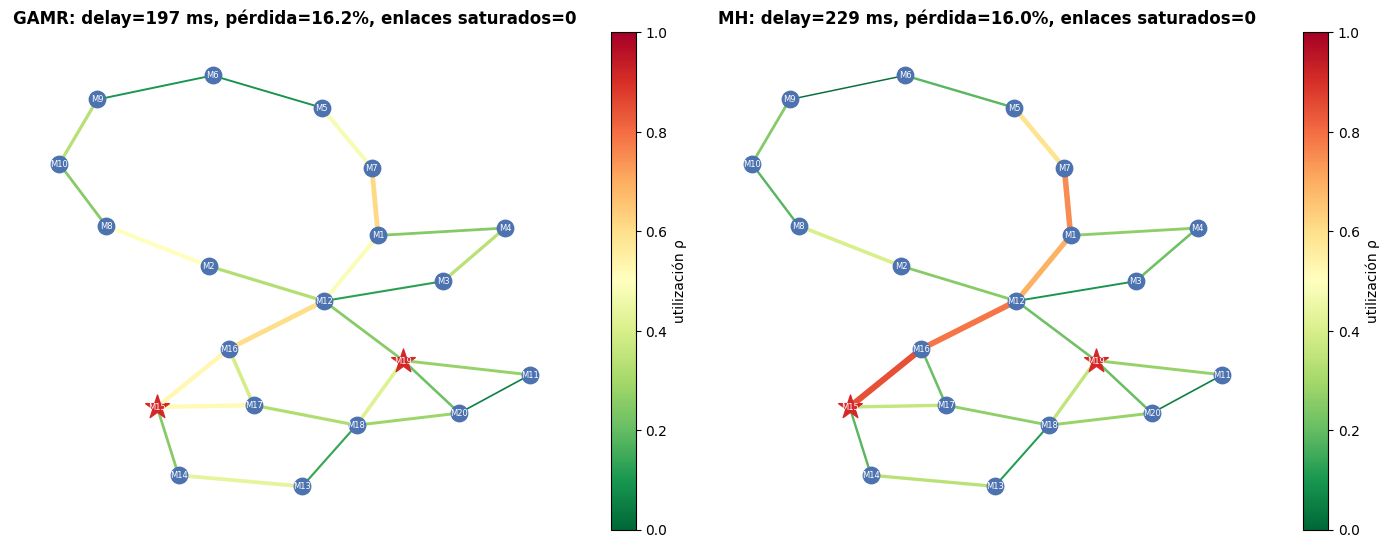

In [42]:
red_mapa = RedSDN(GRAFOS['Oxford'], n_servidores=2, semilla=SEMILLA)
sol_mapa = red_mapa.generar_solicitudes(100, 2)
rutas_mapa = {'GAMR': GAMR(red_mapa, semilla=SEMILLA).resolver(sol_mapa)['rutas'],
              'MH': MinHop(red_mapa).resolver(sol_mapa)['rutas']}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (nombre, rutas) in zip(axes, rutas_mapa.items()):
    _, _, det = Evaluador(red_mapa, sol_mapa).evaluar(rutas, detalle=True)
    q = evaluar_qos(red_mapa, sol_mapa, rutas)
    dibujar_red(ax, red_mapa, POS['Oxford'], f"{nombre}: delay={q['delay_ms']:.0f} ms, pérdida={q['loss_pct']:.1f}%, "
                f"enlaces saturados={q['enlaces_saturados']}", rho=det['rho'])
plt.tight_layout()
guardar_figura(fig, 'fig_exp1_mapa_utilizacion')
plt.show()

## 9. Experimento 2 — Análisis crítico: ¿qué objetivo de "utilización" se optimiza realmente?

La Ec. 4 define $\mathcal{U}^t=\min_{e\in\mathcal{E}}\rho_e$ sobre **todos** los enlaces de la red. Se toma la población final de GAMR del Exp. 1 y se re-evalúa cada individuo con las 4 variantes del objetivo 3. Si un objetivo apenas varía entre individuos, **no discrimina** y la búsqueda se vuelve efectivamente bi-objetivo.

👉 Diapositiva **12** (limitación de la formulación) y banco de preguntas.

,media,desv_est,rango,valores_distintos,coef_variacion_pct
modo_u,,,,,
paper,0.96984,0.00578,0.01709,3,0.59565
activos,0.96793,0.00644,0.02871,6,0.66494
media,0.81907,0.00231,0.00895,79,0.28165
codigo,0.24582,0.01308,0.04059,62,5.32116


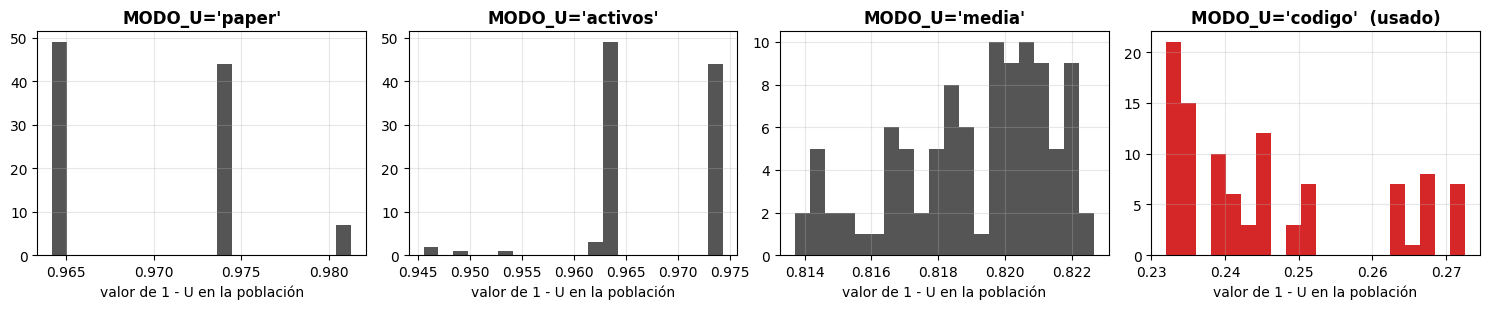

In [43]:
pob = r_g2['poblacion']
filas, valores = [], {}
for modo in ['paper', 'activos', 'media', 'codigo']:
    ev_m = Evaluador(red_e1, sol_e1, modo)
    f3 = np.array([ev_m.evaluar(q.rutas)[0][2] for q in pob])
    valores[modo] = f3
    filas.append(dict(modo_u=modo, media=f3.mean(), desv_est=f3.std(), rango=f3.max() - f3.min(),
                      valores_distintos=len(np.unique(np.round(f3, 6))),
                      coef_variacion_pct=100 * f3.std() / max(abs(f3.mean()), 1e-12)))
tabla_e2 = pd.DataFrame(filas).set_index('modo_u')
guardar_tabla(tabla_e2, 'exp2_objetivo_utilizacion')
display(tabla_e2.round(5))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (modo, f3) in zip(axes, valores.items()):
    ax.hist(f3, bins=20, color='#555555' if modo != MODELO['MODO_U'] else '#d62728')
    ax.set_title(f"MODO_U='{modo}'" + ('  (usado)' if modo == MODELO['MODO_U'] else ''))
    ax.set_xlabel('valor de 1 - U en la población')
plt.tight_layout()
guardar_figura(fig, 'fig_exp2_objetivo_utilizacion')
plt.show()

**Lectura crítica esperada:**
* Con `'paper'` (Ec. 4 literal) el objetivo es casi constante (pocos valores distintos, coeficiente de variación ≈ 0): el mínimo global de utilización lo determina un enlace que casi ninguna ruta usa. **El tercer objetivo no aporta presión selectiva.** Además, con $r^{\text{ref}}=(1,1,1)$ un objetivo pegado a 1 anula el hipervolumen si no se normaliza.
* El **código oficial** de los autores no implementa la Ec. 4: usa un promedio del cuello de botella de cada ruta (`'codigo'`), que sí varía y es coherente con QoS.
* `'media'` también varía, pero premia rutas más largas (más saltos ⇒ más utilización total), lo que entra en conflicto directo con el delay: es un objetivo con incentivo perverso.
* **Conclusión para la presentación:** hay una **inconsistencia entre la formulación matemática publicada y la implementación**, y la Ec. 4 tal como está escrita no es un buen objetivo de optimización.

## 10. Experimento 3 — GAMR vs NSGA-II: HV, IGD y tiempo (≈ Tablas IV–V, Fig. 6–7)

**Diseño:** para cada topología se ejecutan `R_EVO` repeticiones independientes; cada repetición es una **secuencia dinámica** de `T_EVO` intervalos (la red cambia según la Ec. 14 y llegan $N_r=20$ solicitudes nuevas hacia $N_s=5$ servidores). En cada intervalo **ambos algoritmos resuelven exactamente la misma instancia** y se calculan HV/IGD con normalización conjunta.

* **NSGA-II** = mismo código, mismos operadores, misma parada, pero $\alpha=0$ y **sin memoria** → aísla el efecto de la contribución de GAMR (inicialización híbrida + PRSM). Es un *ablation study*.
* El intervalo 1 se reporta aparte: sin memoria, GAMR ≡ NSGA-II.
* Se aplica la **prueba de Wilcoxon de rangos con signo** (pareada) para saber si las diferencias son estadísticamente significativas.

> El paper compara además contra NSGA-III, MOEA/D, AGE, PFG-MOEA y NSGA-II-H (implementados con pymoo/otros). Aquí se compara contra NSGA-II porque es la base de GAMR y la comparación más limpia; los demás requieren adaptar sus operadores a cromosomas de largo variable sobre grafos (fuera del alcance).

In [44]:
def experimento_evolutivos(nombre_topo, R, T, n_r, n_s):
    filas = []
    for rep in range(R):
        red = RedSDN(GRAFOS[nombre_topo], n_s, semilla=SEMILLA + 1000 * rep)
        algoritmos = [GAMR(red, usar_memoria=True, semilla=SEMILLA + 10 * rep + 1),
                      GAMR(red, usar_memoria=False, semilla=SEMILLA + 10 * rep + 2)]
        for t in range(1, T + 1):
            if t > 1:
                red.nuevo_intervalo()
            sol = red.generar_solicitudes(n_r, n_s)
            res = [a.resolver(sol) for a in algoritmos]
            met = metricas_conjuntas({r['nombre']: r['frente'] for r in res})
            for r in res:
                filas.append(dict(topologia=nombre_topo, rep=rep, intervalo=t, algoritmo=r['nombre'],
                                  HV=met[r['nombre']][0], IGD=met[r['nombre']][1], tiempo_s=r['tiempo'],
                                  tiempo_por_solicitud_s=r['tiempo'] / n_r, generaciones=r['generaciones'],
                                  memoria_usada=r['uso_memoria'], tamano_frente=len(r['frente'])))
        print(f'  {nombre_topo}: repetición {rep + 1}/{R} lista')
    return filas


t0 = time.time()
filas = []
for nombre_topo in GRAFOS:
    filas += experimento_evolutivos(nombre_topo, EXP['R_EVO'], EXP['T_EVO'], EXP['NR_EVO'], EXP['NS_EVO'])
df_evo = pd.DataFrame(filas)
df_evo.to_csv(RES_DIR / 'exp3_crudo.csv', index=False)
print(f'Exp. 3 terminado en {time.time() - t0:.0f} s ({len(df_evo)} filas)')

  Oxford: repetición 1/10 lista
  Oxford: repetición 2/10 lista
  Oxford: repetición 3/10 lista
  Oxford: repetición 4/10 lista
  Oxford: repetición 5/10 lista
  Oxford: repetición 6/10 lista
  Oxford: repetición 7/10 lista
  Oxford: repetición 8/10 lista
  Oxford: repetición 9/10 lista
  Oxford: repetición 10/10 lista
  Chinanet: repetición 1/10 lista
  Chinanet: repetición 2/10 lista
  Chinanet: repetición 3/10 lista
  Chinanet: repetición 4/10 lista
  Chinanet: repetición 5/10 lista
  Chinanet: repetición 6/10 lista
  Chinanet: repetición 7/10 lista
  Chinanet: repetición 8/10 lista
  Chinanet: repetición 9/10 lista
  Chinanet: repetición 10/10 lista
Exp. 3 terminado en 432 s (240 filas)


In [45]:
def media_desv(x):
    return f'{np.mean(x):.4f} ± {np.std(x):.4f}'


def resumen_evo(df):
    return df.groupby(['topologia', 'algoritmo']).agg(
        HV=('HV', media_desv), IGD=('IGD', media_desv), tiempo_s=('tiempo_s', media_desv),
        generaciones=('generaciones', 'mean'), n=('HV', 'size'))


con_memoria = df_evo[df_evo.intervalo >= 2]
print('=== Intervalos t ≥ 2 (memoria PRSM activa) — comparable a Tablas IV y V ===')
tabla_e3 = resumen_evo(con_memoria)
display(tabla_e3)
guardar_tabla(tabla_e3, 'exp3_tabla_hv_igd_tiempo')
print('=== Intervalo t = 1 (sin memoria: control, deberían ser equivalentes) ===')
display(resumen_evo(df_evo[df_evo.intervalo == 1]))

try:
    from scipy.stats import wilcoxon
    filas_test = []
    for topo, d in con_memoria.groupby('topologia'):
        piv = d.pivot_table(index=['rep', 'intervalo'], columns='algoritmo', values=['HV', 'IGD', 'tiempo_s'])
        for met in ['HV', 'IGD', 'tiempo_s']:
            a, b = piv[(met, 'GAMR')], piv[(met, 'NSGA-II')]
            p = wilcoxon(a, b).pvalue if len(a) >= 5 and np.any(a != b) else np.nan
            filas_test.append(dict(topologia=topo, metrica=met, GAMR=a.mean(), NSGA_II=b.mean(),
                                   mejora_pct=100 * ((a.mean() - b.mean()) / b.mean() if met == 'HV' else (b.mean() - a.mean()) / b.mean()),
                                   p_valor_wilcoxon=p))
    tabla_test = pd.DataFrame(filas_test).set_index(['topologia', 'metrica'])
    guardar_tabla(tabla_test, 'exp3_wilcoxon')
    print('mejora_pct > 0 => GAMR mejor (HV mayor; IGD y tiempo menores). p < 0.05 => diferencia significativa.')
    display(tabla_test.round(4))
except ImportError:
    print('scipy no instalado: se omite la prueba de Wilcoxon')

=== Intervalos t ≥ 2 (memoria PRSM activa) — comparable a Tablas IV y V ===


HV              IGD         tiempo_s  \
topologia algoritmo                                                      
Chinanet  GAMR       0.6940 ± 0.0611  0.0410 ± 0.0157  2.1837 ± 0.8310   
          NSGA-II    0.6907 ± 0.0604  0.0420 ± 0.0181  2.4599 ± 0.9385   
Oxford    GAMR       0.6700 ± 0.0676  0.0384 ± 0.0269  1.0934 ± 0.3319   
          NSGA-II    0.6726 ± 0.0676  0.0347 ± 0.0202  1.3288 ± 0.3700   

                     generaciones   n  
topologia algoritmo                    
Chinanet  GAMR              62.82  50  
          NSGA-II           68.36  50  
Oxford    GAMR              36.36  50  
          NSGA-II           44.52  50

=== Intervalo t = 1 (sin memoria: control, deberían ser equivalentes) ===


HV              IGD         tiempo_s  \
topologia algoritmo                                                      
Chinanet  GAMR       0.6844 ± 0.0711  0.0365 ± 0.0253  2.6720 ± 0.9059   
          NSGA-II    0.6962 ± 0.0730  0.0374 ± 0.0152  2.3064 ± 0.5652   
Oxford    GAMR       0.6823 ± 0.0507  0.0334 ± 0.0207  1.3590 ± 0.5053   
          NSGA-II    0.6707 ± 0.0452  0.0427 ± 0.0184  1.2982 ± 0.3113   

                     generaciones   n  
topologia algoritmo                    
Chinanet  GAMR               70.9  10  
          NSGA-II            65.0  10  
Oxford    GAMR               42.2  10  
          NSGA-II            43.2  10

mejora_pct > 0 => GAMR mejor (HV mayor; IGD y tiempo menores). p < 0.05 => diferencia significativa.


GAMR  NSGA_II  mejora_pct  p_valor_wilcoxon
topologia metrica                                                
Chinanet  HV        0.6940   0.6907      0.4681            0.8633
          IGD       0.0410   0.0420      2.3245            0.9086
          tiempo_s  2.1837   2.4599     11.2268            0.0594
Oxford    HV        0.6700   0.6726     -0.3823            0.8333
          IGD       0.0384   0.0347    -10.5286            0.7961
          tiempo_s  1.0934   1.3288     17.7161            0.0000

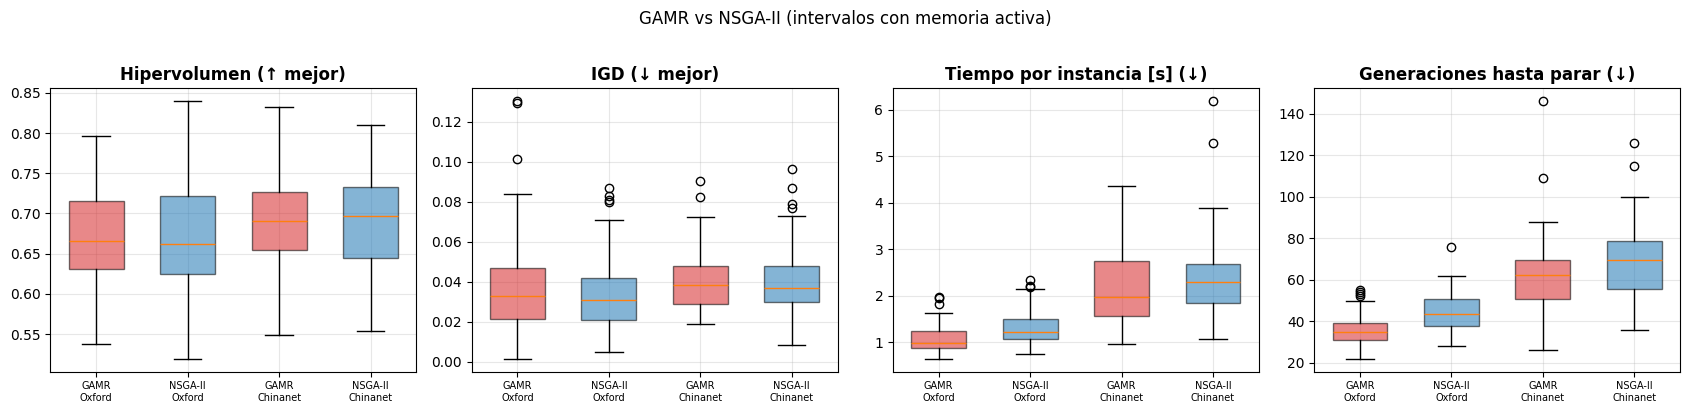

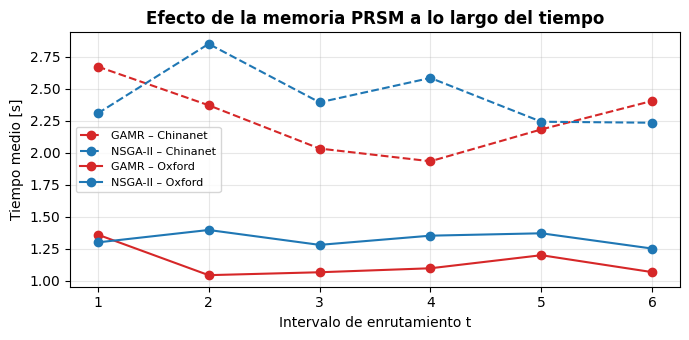

In [46]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
orden = ['GAMR', 'NSGA-II']
for ax, (met, titulo) in zip(axes, [('HV', 'Hipervolumen (↑ mejor)'), ('IGD', 'IGD (↓ mejor)'),
                                    ('tiempo_s', 'Tiempo por instancia [s] (↓)'), ('generaciones', 'Generaciones hasta parar (↓)')]):
    datos, etiquetas, colores = [], [], []
    for topo in GRAFOS:
        for alg in orden:
            datos.append(con_memoria[(con_memoria.topologia == topo) & (con_memoria.algoritmo == alg)][met].values)
            etiquetas.append(f'{alg}\n{topo}')
            colores.append(COLORES[alg])
    bp = ax.boxplot(datos, patch_artist=True, widths=0.6)
    for caja, c in zip(bp['boxes'], colores):
        caja.set_facecolor(c); caja.set_alpha(0.55)
    ax.set_xticks(range(1, len(etiquetas) + 1), etiquetas, fontsize=7)
    ax.set_title(titulo)
plt.suptitle('GAMR vs NSGA-II (intervalos con memoria activa)', y=1.02)
plt.tight_layout()
guardar_figura(fig, 'fig_exp3_hv_igd_tiempo')
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
evol = df_evo.groupby(['topologia', 'algoritmo', 'intervalo']).tiempo_s.mean().reset_index()
for (topo, alg), d in evol.groupby(['topologia', 'algoritmo']):
    ax.plot(d.intervalo, d.tiempo_s, marker='o', ls='-' if topo == 'Oxford' else '--', color=COLORES[alg], label=f'{alg} – {topo}')
ax.set_xlabel('Intervalo de enrutamiento t'); ax.set_ylabel('Tiempo medio [s]')
ax.set_title('Efecto de la memoria PRSM a lo largo del tiempo')
ax.legend(fontsize=8)
plt.tight_layout()
guardar_figura(fig, 'fig_exp3_tiempo_por_intervalo')
plt.show()

**Cómo interpretar / qué decir en la diapositiva 9:**
* **HV ↑ e IGD ↓** indican un frente más cercano y mejor distribuido respecto del frente de referencia $\mathcal{F}^*$ (unión de ambos algoritmos).
* El **tiempo** y las **generaciones** miden el efecto de la memoria + parada temprana: el paper reporta un ahorro medio de **14.4 % frente a NSGA-II**. Compara tu `mejora_pct` de `tiempo_s` con ese valor.
* En $t=1$ ambos deben ser estadísticamente iguales (control experimental). Si no lo son, es solo ruido (semillas distintas).
* Los tiempos absolutos (segundos) son mayores que los 0.19–0.35 s del paper porque esta implementación es Python puro sin optimizar y con otro hardware; la comparación válida es **relativa**.
* Si GAMR no mejora el HV/IGD en tu corrida, **es un hallazgo legítimo**: la memoria acelera la convergencia pero puede reducir la diversidad inicial (todas las rutas PSBI comparten el tramo memorizado). Úsalo en el análisis crítico.

## 11. Experimento 4 — Métricas de red QoS vs Min-Hop y LCP-WAC* (≈ Fig. 8, 9 y 10)

**Diseño (igual que el paper):** $N_s\in\{15,5,2\}$ servidores × $N_r\in\{10,20,50,100\}$ solicitudes simultáneas, en Oxford y Chinanet, con $\beta=20\%$. Cada configuración es una secuencia de `T_QOS` intervalos; GAMR conserva su memoria entre intervalos y LCP-WAC* su historial. Se reportan los intervalos $t\ge2$ (memoria e historial disponibles).

Métricas "medidas" sobre la configuración instalada (modelo fluido de la Sección 3):
* **Delay medio** (Fig. 8) y **pérdida media** (Fig. 9) por solicitud.
* **Utilización media de enlaces** (Fig. 10) y **% de enlaces del núcleo que transportan tráfico** (indicador directo de reparto de carga).
* **Tiempo de GAMR por solicitud** vs $N_s$ (tendencia de la Fig. 7: más servidores ⇒ ¿menos tiempo?).

Escenario crítico del paper: **$N_s=2$, $N_r=100$** (pocos servidores, mucha demanda → congestión cerca de los servidores).

In [47]:
def experimento_qos(nombre_topo, lista_ns, lista_nr, T, R, beta, nr_fijo=None):
    filas = []
    for n_s in lista_ns:
        for n_r in lista_nr:
            for rep in range(R):
                red = RedSDN(GRAFOS[nombre_topo], n_s, beta=beta, semilla=SEMILLA + 1000 * rep)
                algoritmos = [GAMR(red, semilla=SEMILLA + rep), MinHop(red), LCPWACProxy(red)]
                for t in range(1, T + 1):
                    if t > 1:
                        red.nuevo_intervalo()
                    sol = red.generar_solicitudes(n_r, n_s)
                    for a in algoritmos:
                        r = a.resolver(sol)
                        filas.append(dict(topologia=nombre_topo, beta=beta, N_s=n_s, N_r=n_r, rep=rep, intervalo=t,
                                          algoritmo=r['nombre'], tiempo_s=r['tiempo'],
                                          **evaluar_qos(red, sol, r['rutas'])))
        print(f'  {nombre_topo}: N_s={n_s} listo')
    return filas


t0 = time.time()
filas = []
for nombre_topo in GRAFOS:
    filas += experimento_qos(nombre_topo, EXP['NS_QOS'], EXP['NR_QOS'], EXP['T_QOS'], EXP['R_QOS'], MODELO['BETA_DEFECTO'])
df_qos = pd.DataFrame(filas)
df_qos.to_csv(RES_DIR / 'exp4_crudo.csv', index=False)
print(f'Exp. 4 terminado en {time.time() - t0:.0f} s ({len(df_qos)} filas)')

  Oxford: N_s=15 listo
  Oxford: N_s=5 listo
  Oxford: N_s=2 listo
  Chinanet: N_s=15 listo
  Chinanet: N_s=5 listo
  Chinanet: N_s=2 listo
Exp. 4 terminado en 793 s (720 filas)


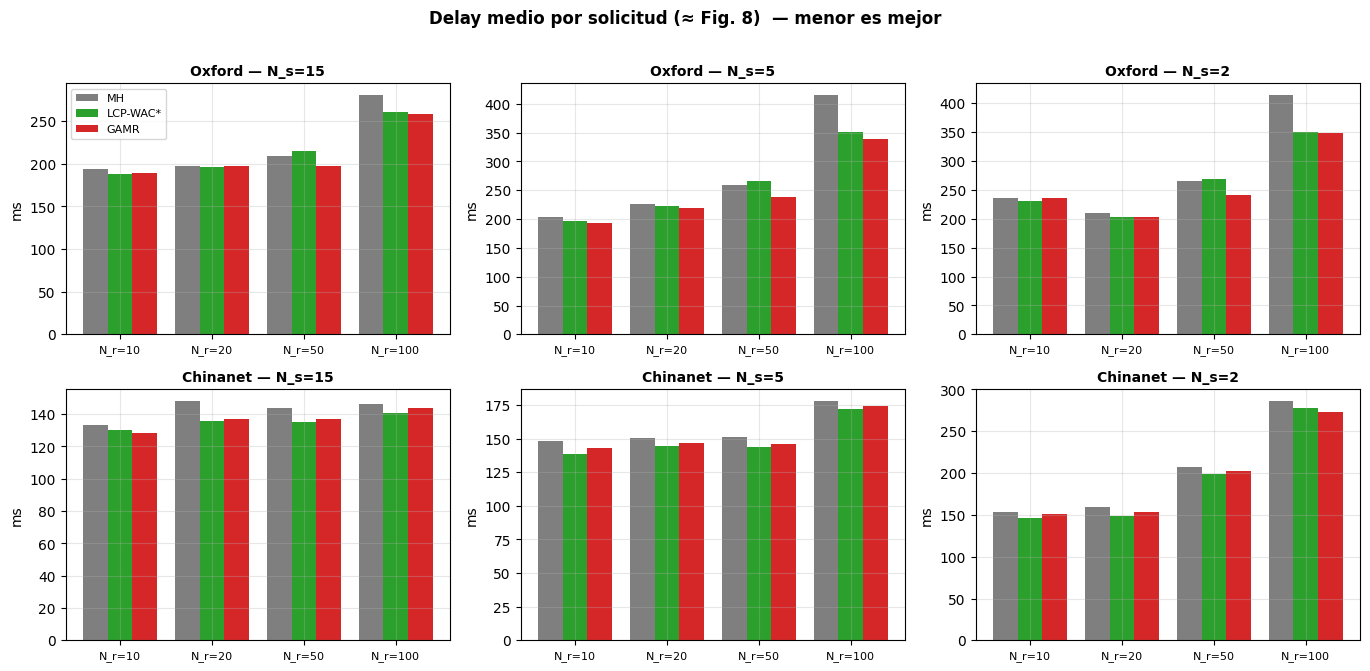

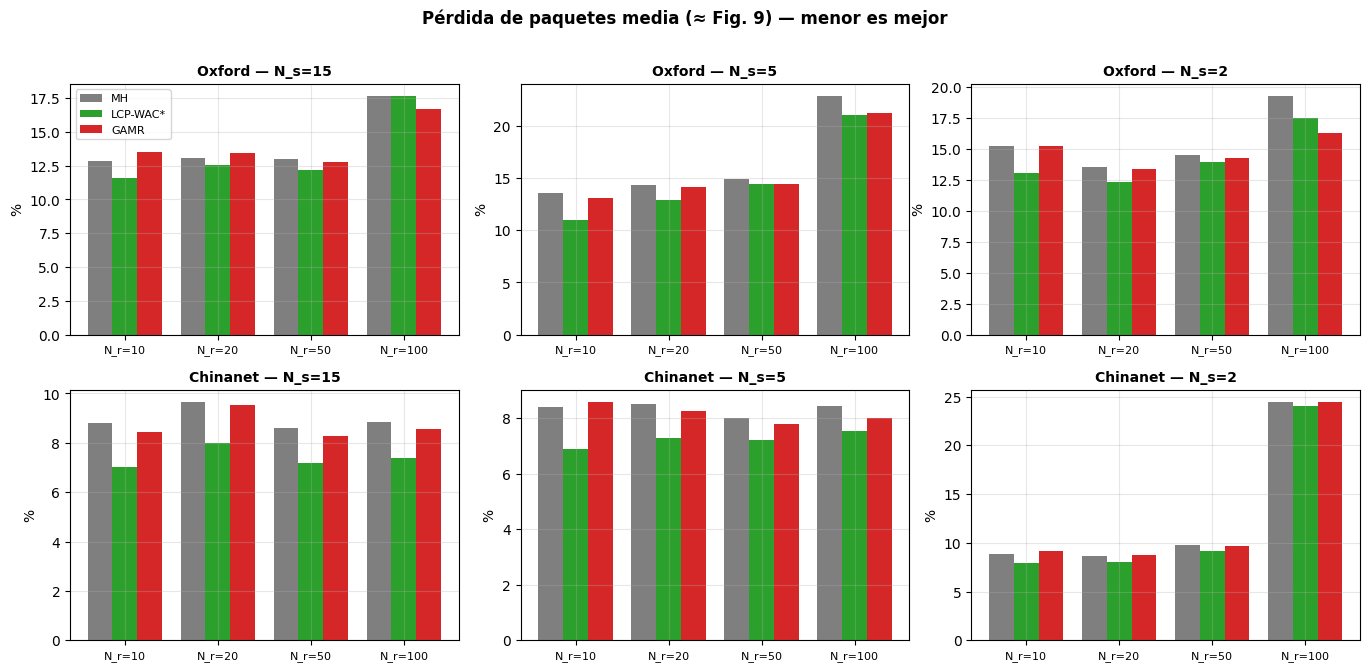

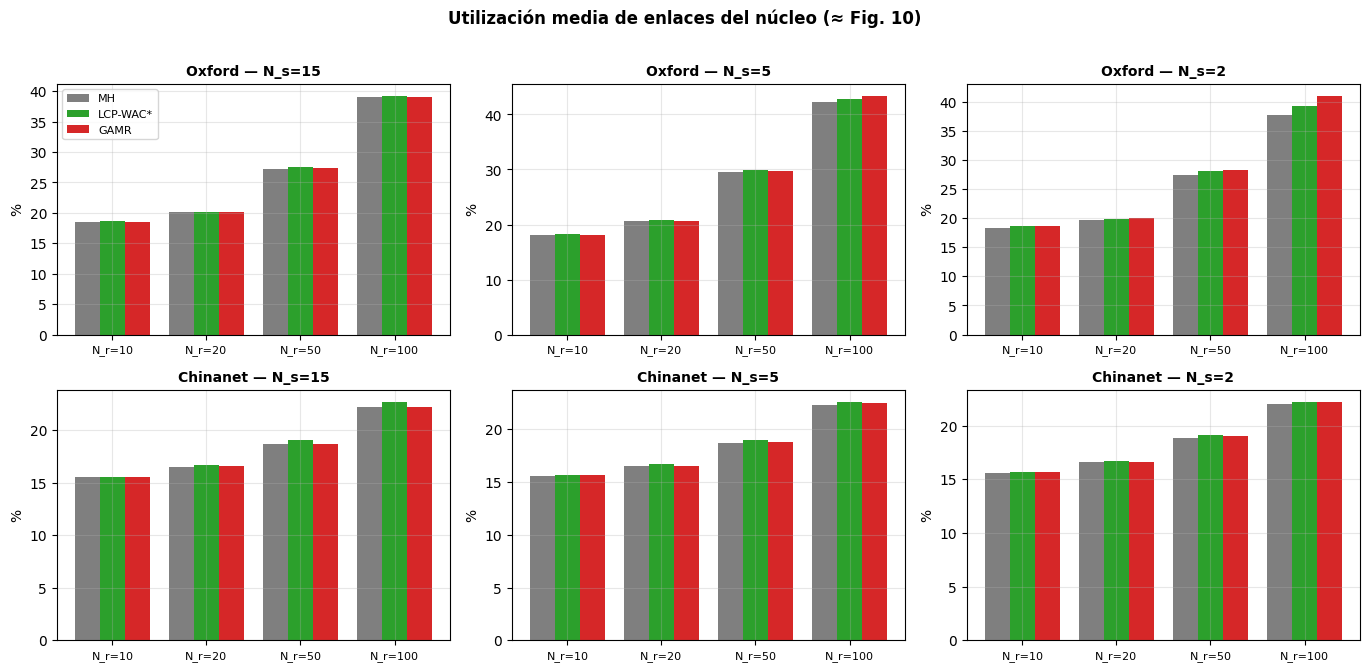

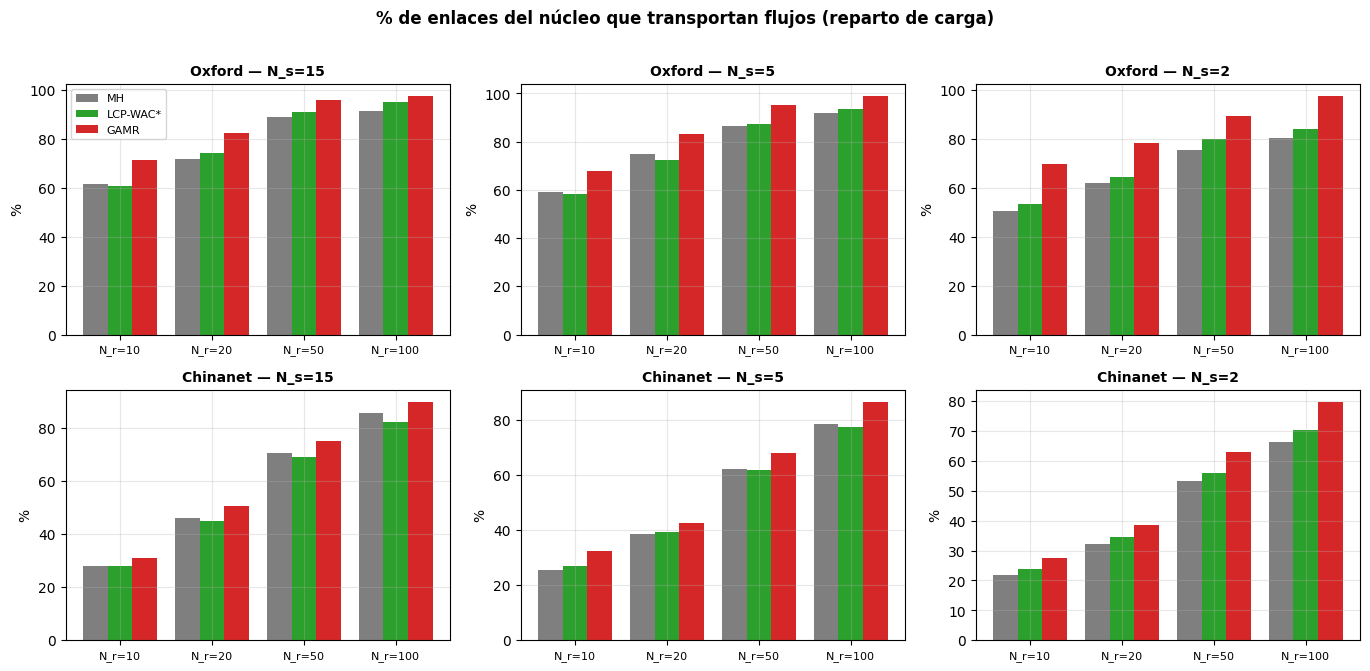

In [48]:
ORDEN_ALG = ['MH', 'LCP-WAC*', 'GAMR']
qos = df_qos[df_qos.intervalo >= 2]
tabla_e4 = qos.groupby(['topologia', 'N_s', 'N_r', 'algoritmo'])[
    ['delay_ms', 'loss_pct', 'util_pct', 'enlaces_usados_pct', 'enlaces_saturados', 'saltos']].mean().round(2)
guardar_tabla(tabla_e4, 'exp4_tabla_qos')


def barras_qos(metrica, titulo, nombre_fig, ylabel):
    topos, lista_ns, lista_nr = list(GRAFOS), EXP['NS_QOS'], EXP['NR_QOS']
    fig, axes = plt.subplots(len(topos), len(lista_ns), figsize=(4.6 * len(lista_ns), 3.3 * len(topos)), squeeze=False)
    ancho = 0.8 / len(ORDEN_ALG)
    x = np.arange(len(lista_nr))
    for i, topo in enumerate(topos):
        for j, n_s in enumerate(lista_ns):
            ax = axes[i, j]
            d = qos[(qos.topologia == topo) & (qos.N_s == n_s)].groupby(['N_r', 'algoritmo'])[metrica].mean()
            for k, alg in enumerate(ORDEN_ALG):
                ax.bar(x + (k - 1) * ancho, [d.get((nr, alg), np.nan) for nr in lista_nr], ancho,
                       color=COLORES[alg], label=alg)
            ax.set_xticks(x, [f'N_r={nr}' for nr in lista_nr], fontsize=8)
            ax.set_title(f'{topo} — N_s={n_s}', fontsize=10)
            ax.set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(titulo, y=1.01, fontweight='bold')
    plt.tight_layout()
    guardar_figura(fig, nombre_fig)
    plt.show()


barras_qos('delay_ms', 'Delay medio por solicitud (≈ Fig. 8)  — menor es mejor', 'fig_exp4_delay', 'ms')
barras_qos('loss_pct', 'Pérdida de paquetes media (≈ Fig. 9) — menor es mejor', 'fig_exp4_loss', '%')
barras_qos('util_pct', 'Utilización media de enlaces del núcleo (≈ Fig. 10)', 'fig_exp4_utilizacion', '%')
barras_qos('enlaces_usados_pct', '% de enlaces del núcleo que transportan flujos (reparto de carga)', 'fig_exp4_enlaces_usados', '%')

Escenario crítico N_s=2, N_r=100 (paper, Oxford: MH 118.9 ms / LCP-WAC 105.6 ms / GAMR 76.9 ms):


delay_ms  loss_pct  util_pct  enlaces_saturados
topologia algoritmo                                                 
Chinanet  GAMR         272.85     24.48     22.23               1.00
          LCP-WAC*     278.24     24.06     22.17               1.12
          MH           285.88     24.49     21.98               1.12
Oxford    GAMR         348.14     16.23     40.98               1.00
          LCP-WAC*     350.92     17.49     39.29               0.88
          MH           413.60     19.27     37.66               1.50

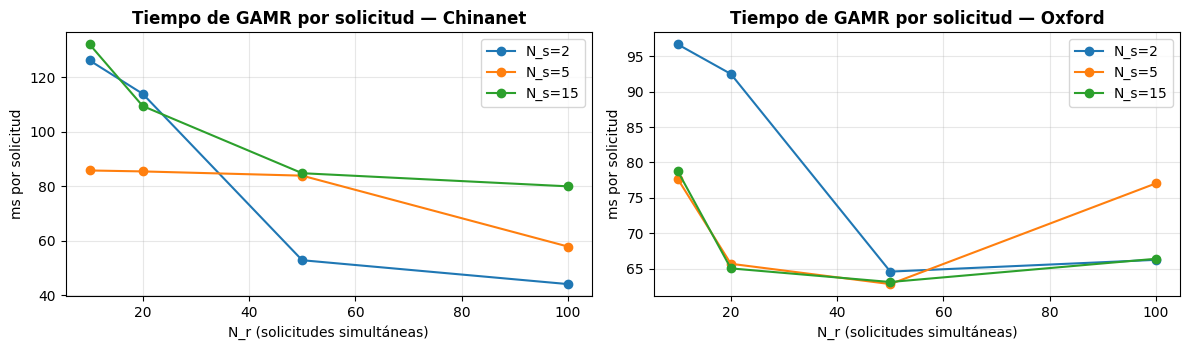

In [49]:
critico = qos[(qos.N_s == min(EXP['NS_QOS'])) & (qos.N_r == max(EXP['NR_QOS']))]
tabla_critica = critico.groupby(['topologia', 'algoritmo'])[['delay_ms', 'loss_pct', 'util_pct', 'enlaces_saturados']].mean().round(2)
print(f"Escenario crítico N_s={min(EXP['NS_QOS'])}, N_r={max(EXP['NR_QOS'])} (paper, Oxford: MH 118.9 ms / LCP-WAC 105.6 ms / GAMR 76.9 ms):")
display(tabla_critica)
guardar_tabla(tabla_critica, 'exp4_escenario_critico')

gamr_t = qos[qos.algoritmo == 'GAMR'].groupby(['topologia', 'N_s', 'N_r']).tiempo_s.mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, (topo, d) in zip(axes, gamr_t.groupby('topologia')):
    for n_s, dd in d.groupby('N_s'):
        ax.plot(dd.N_r, dd.tiempo_s / dd.N_r * 1000, marker='o', label=f'N_s={n_s}')
    ax.set_xlabel('N_r (solicitudes simultáneas)'); ax.set_ylabel('ms por solicitud')
    ax.set_title(f'Tiempo de GAMR por solicitud — {topo}')
    ax.legend()
plt.tight_layout()
guardar_figura(fig, 'fig_exp4_tiempo_gamr')
plt.show()

**Cómo interpretar / qué decir en la diapositiva 10:**
* Con **pocas solicitudes** ($N_r=10$) los tres algoritmos son parecidos: no hay congestión y el camino más corto ya es bueno.
* Al subir $N_r$ y bajar $N_s$, Min-Hop **concentra** todo el tráfico en los mismos caminos → saturación → delay de cola y pérdidas por desborde. GAMR, al optimizar en conjunto las $N_r$ rutas (cromosoma multi-solicitud) y elegir la de **menor solapamiento**, reparte la carga (más enlaces usados, menos enlaces saturados).
* LCP-WAC* (costo ponderado + carga prevista) es un competidor **fuerte con carga baja o moderada** (puede igualar o superar a GAMR); la ventaja de GAMR aparece sobre todo en los escenarios de **alta carga** ($N_r=100$), especialmente en Oxford, que tiene pocos caminos alternativos.
* En Chinanet (más mallada, diámetro 4) los caminos cortos ya reparten bien la carga y las diferencias son menores: es una observación útil para la crítica (el beneficio de GAMR depende de la topología).
* El **tiempo por solicitud** de GAMR suele **bajar** al crecer $N_r$ (el costo fijo de la población se amortiza): argumento de escalabilidad del paper.
* Compara las **tendencias** con las Fig. 8–10 del paper, no los valores absolutos (el modelo de red es distinto a Mininet).

## 12. Experimento 5 — Robustez ante desorden del ancho de banda $\beta$ (≈ Fig. 11)

Chinanet en el escenario de carga alta ($N_s=2$, $N_r=100$, donde la elección de rutas importa), $\beta\in\{0,5,20,55\}\%$ (Ec. 14). Con $\beta=0$ la red es homogénea y estable: **la predicción histórica de LCP-WAC\* es exacta**. Con $\beta=55\%$ el ancho de banda de cada enlace cambia hasta ±55 % entre intervalos: la predicción queda obsoleta, mientras GAMR **re-optimiza con la medición actual** del monitoreo. Paper: con $\beta=0$ LCP-WAC obtiene el menor delay (71.32 ms), pero con $\beta=55\%$ MH y LCP-WAC llegan a 88.4 % y 76.4 % de pérdida vs ~15 % de GAMR.

  Chinanet: N_s=2 listo
  Chinanet: N_s=2 listo
  Chinanet: N_s=2 listo
  Chinanet: N_s=2 listo
Exp. 5 terminado en 412 s


delay_ms  loss_pct  util_pct  enlaces_saturados  viol_bw_pct
beta algoritmo                                                              
0.00 GAMR         215.91      9.07     21.09               0.40          0.0
     LCP-WAC*     210.44      8.49     21.01               0.40          0.0
     MH           244.55      9.78     20.62               0.60          0.0
0.05 GAMR         215.81     18.85     22.08               0.67          0.0
     LCP-WAC*     218.35     18.03     22.01               0.73          0.0
     MH           229.75     18.82     21.81               0.73          0.0
0.20 GAMR         217.78     18.29     22.15               0.67          0.0
     LCP-WAC*     221.81     17.53     22.06               0.80          0.0
     MH           230.90     18.31     21.85               0.73          0.0
0.55 GAMR         230.34     18.11     22.66               0.80          0.0
     LCP-WAC*     248.04     18.26     22.60               1.07          0.0
     MH           249.04     18.54     22.34               1.07          0.0

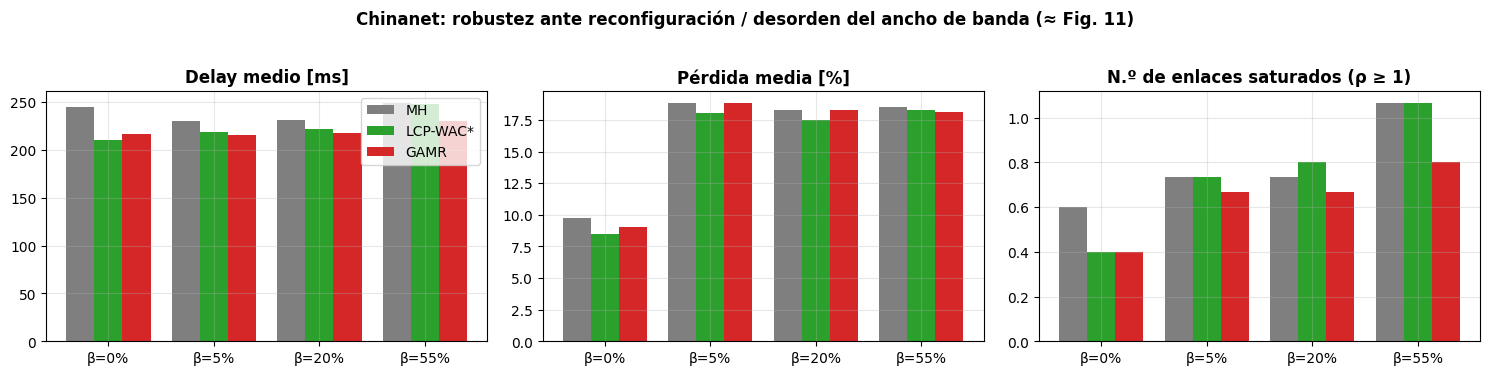

In [50]:
t0 = time.time()
filas = []
for beta in EXP['BETAS']:
    filas += experimento_qos('Chinanet', [EXP['NS_BETA']], [EXP['NR_BETA']], EXP['T_BETA'], EXP['R_BETA'], beta)
df_beta = pd.DataFrame(filas)
df_beta.to_csv(RES_DIR / 'exp5_crudo.csv', index=False)
print(f'Exp. 5 terminado en {time.time() - t0:.0f} s')

beta_q = df_beta[df_beta.intervalo >= 2]
tabla_e5 = beta_q.groupby(['beta', 'algoritmo'])[['delay_ms', 'loss_pct', 'util_pct', 'enlaces_saturados', 'viol_bw_pct']].mean().round(2)
guardar_tabla(tabla_e5, 'exp5_tabla_beta')
display(tabla_e5)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
x = np.arange(len(EXP['BETAS']))
ancho = 0.8 / len(ORDEN_ALG)
for ax, (met, titulo) in zip(axes, [('delay_ms', 'Delay medio [ms]'), ('loss_pct', 'Pérdida media [%]'),
                                    ('enlaces_saturados', 'N.º de enlaces saturados (ρ ≥ 1)')]):
    d = beta_q.groupby(['beta', 'algoritmo'])[met].mean()
    for k, alg in enumerate(ORDEN_ALG):
        ax.bar(x + (k - 1) * ancho, [d.get((b, alg), np.nan) for b in EXP['BETAS']], ancho, color=COLORES[alg], label=alg)
    ax.set_xticks(x, [f'β={int(100 * b)}%' for b in EXP['BETAS']])
    ax.set_title(titulo)
axes[0].legend()
fig.suptitle('Chinanet: robustez ante reconfiguración / desorden del ancho de banda (≈ Fig. 11)', y=1.03, fontweight='bold')
plt.tight_layout()
guardar_figura(fig, 'fig_exp5_beta')
plt.show()

**Cómo interpretar:** observa cómo cambia la **brecha** entre LCP-WAC* y GAMR al aumentar $\beta$. Si con $\beta=0$ LCP-WAC* empata o gana (como en el paper) y con $\beta$ alto pasa a perder frente a GAMR, se reproduce **cualitativamente** la conclusión del paper: **los métodos que dependen de una predicción entrenada/histórica son frágiles ante cambios de distribución, mientras la búsqueda poblacional re-optimiza sobre el estado actual**. En el modelo fluido la diferencia es moderada y la pérdida queda dominada por el enlace de acceso al servidor (inevitable para cualquier algoritmo); el colapso del paper (76–88 % de pérdida) depende de la dinámica de Mininet/TCP y no se espera reproducirlo aquí. Decirlo así es más honesto (y más defendible ante la comisión) que forzar el resultado.

## 13. Experimento 6 — Sensibilidad al parámetro $\alpha$ (exploración vs explotación)

$\alpha$ controla la probabilidad de usar PSBI (memoria) en vez de RSBI (aleatorio). El paper lo fija en $0.5$ **sin estudio de sensibilidad**. Aquí se barre $\alpha\in\{0,0.25,0.5,0.75,1\}$ en Oxford ($N_r=20$, $N_s=5$): todas las variantes resuelven las mismas instancias y el HV/IGD se normaliza en conjunto.

* $\alpha=0$ → solo exploración (≡ NSGA-II). $\alpha=1$ → solo explotación de la memoria (riesgo de **pérdida de diversidad / convergencia prematura**).
* 👉 Respalda la extensión propuesta en la diapositiva **12**: **$\alpha$ auto-adaptativo** según la entropía de la red ($\beta$) o la tasa de cambio del estado.

Exp. 6 terminado en 156 s


HV             IGD         tiempo_s         generaciones           \
         mean     std    mean     std     mean     std         mean      std   
alpha                                                                          
0.00   0.6911  0.0741  0.0429  0.0190   1.2506  0.3193        43.56  11.2178   
0.25   0.6984  0.0585  0.0415  0.0238   1.0927  0.3064        38.64   9.6905   
0.50   0.6950  0.0704  0.0394  0.0118   1.0629  0.2870        37.48  10.1124   
0.75   0.6499  0.0711  0.0717  0.0470   0.9249  0.2281        33.92   8.6116   
1.00   0.3616  0.1743  0.3186  0.1966   0.6558  0.1899        25.24   6.5909   

       delay_ms          loss_pct          
           mean      std     mean     std  
alpha                                      
0.00   192.4968  30.7879  12.0015  3.9174  
0.25   190.0734  29.1443  11.9301  3.8314  
0.50   191.2599  30.4945  11.8143  3.8932  
0.75   191.3060  30.4735  11.9297  3.7860  
1.00   195.2258  32.1392  11.9777  3.7143

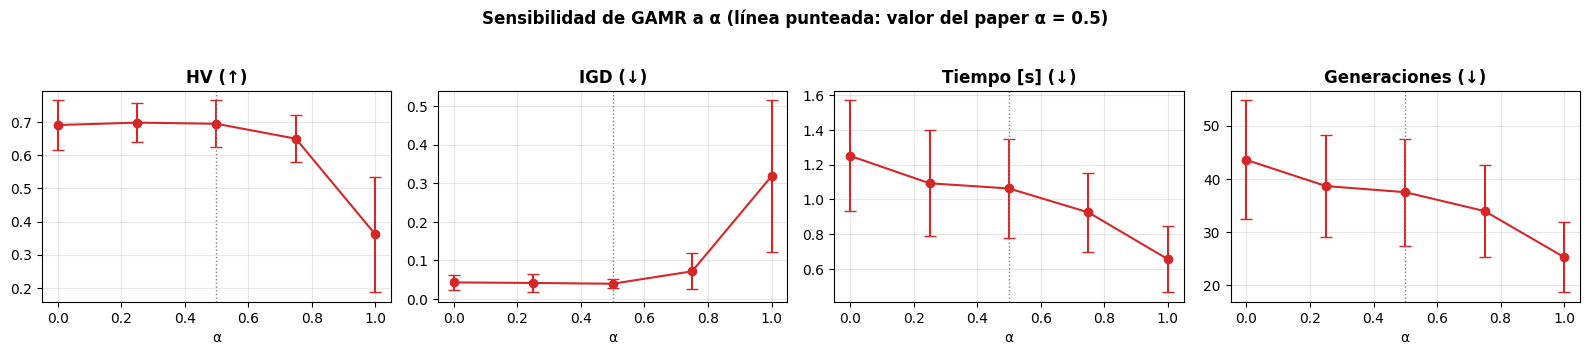

In [51]:
t0 = time.time()
filas = []
for rep in range(EXP['R_ALPHA']):
    red = RedSDN(GRAFOS['Oxford'], EXP['NS_EVO'], semilla=SEMILLA + 1000 * rep)
    variantes = {a: GAMR(red, alpha=a, semilla=SEMILLA + 10 * rep + i, nombre=f'α={a}') for i, a in enumerate(EXP['ALPHAS'])}
    for t in range(1, EXP['T_ALPHA'] + 1):
        if t > 1:
            red.nuevo_intervalo()
        sol = red.generar_solicitudes(EXP['NR_EVO'], EXP['NS_EVO'])
        res = {a: g.resolver(sol) for a, g in variantes.items()}
        met = metricas_conjuntas({a: r['frente'] for a, r in res.items()})
        for a, r in res.items():
            filas.append(dict(rep=rep, intervalo=t, alpha=a, HV=met[a][0], IGD=met[a][1], tiempo_s=r['tiempo'],
                              generaciones=r['generaciones'], delay_ms=r['F'][0], loss_pct=100 * r['F'][1]))
df_alpha = pd.DataFrame(filas)
df_alpha.to_csv(RES_DIR / 'exp6_crudo.csv', index=False)
print(f'Exp. 6 terminado en {time.time() - t0:.0f} s')

tabla_e6 = df_alpha[df_alpha.intervalo >= 2].groupby('alpha')[['HV', 'IGD', 'tiempo_s', 'generaciones', 'delay_ms', 'loss_pct']].agg(['mean', 'std'])
guardar_tabla(tabla_e6, 'exp6_tabla_alpha')
display(tabla_e6.round(4))

d = df_alpha[df_alpha.intervalo >= 2].groupby('alpha')
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (met, titulo) in zip(axes, [('HV', 'HV (↑)'), ('IGD', 'IGD (↓)'), ('tiempo_s', 'Tiempo [s] (↓)'), ('generaciones', 'Generaciones (↓)')]):
    m, s = d[met].mean(), d[met].std()
    ax.errorbar(m.index, m.values, yerr=s.values, marker='o', capsize=4, color='#d62728')
    ax.axvline(0.5, color='gray', ls=':', lw=1)
    ax.set_xlabel('α'); ax.set_title(titulo)
fig.suptitle('Sensibilidad de GAMR a α (línea punteada: valor del paper α = 0.5)', y=1.03, fontweight='bold')
plt.tight_layout()
guardar_figura(fig, 'fig_exp6_alpha')
plt.show()

## 14. Resumen automático de resultados (frases listas para las diapositivas)

Esta celda calcula los números clave a partir de **tus** corridas y los compara con lo reportado en el paper. Cópialos a las diapositivas 9 y 10 indicando siempre *"en nuestra réplica en simulación"*.

In [52]:
def pct(nuevo, base):
    return 100 * (base - nuevo) / base


lineas = ['### Resultados de la réplica (modo ' + MODO + ')', '']
lineas.append('**GAMR vs NSGA-II (intervalos con memoria, Exp. 3)** — paper: HV +3.4 a 22.8 %, IGD −33 a 86 %, tiempo −14.4 % vs NSGA-II')
for topo, dd in con_memoria.groupby('topologia'):
    g, n = dd[dd.algoritmo == 'GAMR'], dd[dd.algoritmo == 'NSGA-II']
    lineas.append(f'- {topo}: HV {g.HV.mean():.3f} vs {n.HV.mean():.3f} ({100 * (g.HV.mean() - n.HV.mean()) / n.HV.mean():+.1f} %), '
                  f'IGD {g.IGD.mean():.4f} vs {n.IGD.mean():.4f} ({-pct(g.IGD.mean(), n.IGD.mean()):+.1f} %), '
                  f'tiempo {g.tiempo_s.mean():.2f} s vs {n.tiempo_s.mean():.2f} s ({-pct(g.tiempo_s.mean(), n.tiempo_s.mean()):+.1f} %), '
                  f'generaciones {g.generaciones.mean():.0f} vs {n.generaciones.mean():.0f}')

lineas += ['', f"**Escenario crítico N_s={min(EXP['NS_QOS'])}, N_r={max(EXP['NR_QOS'])} (Exp. 4)** — paper (Oxford): delay MH 118.91 / LCP-WAC 105.64 / GAMR 76.92 ms"]
for topo, dd in critico.groupby('topologia'):
    m = dd.groupby('algoritmo')[['delay_ms', 'loss_pct', 'enlaces_saturados']].mean()
    lineas.append(f"- {topo}: delay MH {m.loc['MH', 'delay_ms']:.1f} / LCP-WAC* {m.loc['LCP-WAC*', 'delay_ms']:.1f} / GAMR {m.loc['GAMR', 'delay_ms']:.1f} ms "
                  f"(GAMR {-pct(m.loc['GAMR', 'delay_ms'], m.loc['MH', 'delay_ms']):+.1f} % vs MH); "
                  f"pérdida MH {m.loc['MH', 'loss_pct']:.1f} / LCP-WAC* {m.loc['LCP-WAC*', 'loss_pct']:.1f} / GAMR {m.loc['GAMR', 'loss_pct']:.1f} %")

lineas += ['', '**Robustez a β (Exp. 5, Chinanet)** — paper: con β=55 % pérdida MH 88.4 % / LCP-WAC 76.4 % vs GAMR ~15 %']
for beta, dd in beta_q.groupby('beta'):
    m = dd.groupby('algoritmo')[['delay_ms', 'loss_pct']].mean()
    lineas.append(f"- β={int(100 * beta)} %: delay MH {m.loc['MH', 'delay_ms']:.1f} / LCP-WAC* {m.loc['LCP-WAC*', 'delay_ms']:.1f} / GAMR {m.loc['GAMR', 'delay_ms']:.1f} ms; "
                  f"pérdida MH {m.loc['MH', 'loss_pct']:.1f} / LCP-WAC* {m.loc['LCP-WAC*', 'loss_pct']:.1f} / GAMR {m.loc['GAMR', 'loss_pct']:.1f} %")

ma = df_alpha[df_alpha.intervalo >= 2].groupby('alpha')[['HV', 'tiempo_s']].mean()
lineas += ['', f"**Sensibilidad a α (Exp. 6)**: mejor HV con α={ma.HV.idxmax()} ({ma.HV.max():.3f}); menor tiempo con α={ma.tiempo_s.idxmin()} ({ma.tiempo_s.min():.2f} s); α=0.5 → HV {ma.loc[0.5, 'HV']:.3f}, {ma.loc[0.5, 'tiempo_s']:.2f} s"]

resumen_md = '\n'.join(lineas)
(RES_DIR / 'resumen_resultados.md').write_text(resumen_md, encoding='utf-8')
display(Markdown(resumen_md))
print('\nArchivos generados en', RES_DIR)
for f in sorted(RES_DIR.iterdir()):
    print('  ', f.name)

### Resultados de la réplica (modo COMPLETO)

**GAMR vs NSGA-II (intervalos con memoria, Exp. 3)** — paper: HV +3.4 a 22.8 %, IGD −33 a 86 %, tiempo −14.4 % vs NSGA-II
- Chinanet: HV 0.694 vs 0.691 (+0.5 %), IGD 0.0410 vs 0.0420 (-2.3 %), tiempo 2.18 s vs 2.46 s (-11.2 %), generaciones 63 vs 68
- Oxford: HV 0.670 vs 0.673 (-0.4 %), IGD 0.0384 vs 0.0347 (+10.5 %), tiempo 1.09 s vs 1.33 s (-17.7 %), generaciones 36 vs 45

**Escenario crítico N_s=2, N_r=100 (Exp. 4)** — paper (Oxford): delay MH 118.91 / LCP-WAC 105.64 / GAMR 76.92 ms
- Chinanet: delay MH 285.9 / LCP-WAC* 278.2 / GAMR 272.9 ms (GAMR -4.6 % vs MH); pérdida MH 24.5 / LCP-WAC* 24.1 / GAMR 24.5 %
- Oxford: delay MH 413.6 / LCP-WAC* 350.9 / GAMR 348.1 ms (GAMR -15.8 % vs MH); pérdida MH 19.3 / LCP-WAC* 17.5 / GAMR 16.2 %

**Robustez a β (Exp. 5, Chinanet)** — paper: con β=55 % pérdida MH 88.4 % / LCP-WAC 76.4 % vs GAMR ~15 %
- β=0 %: delay MH 244.6 / LCP-WAC* 210.4 / GAMR 215.9 ms; pérdida MH 9.8 / LCP-WAC* 8.5 / GAMR 9.1 %
- β=5 %: delay MH 229.8 / LCP-WAC* 218.3 / GAMR 215.8 ms; pérdida MH 18.8 / LCP-WAC* 18.0 / GAMR 18.9 %
- β=20 %: delay MH 230.9 / LCP-WAC* 221.8 / GAMR 217.8 ms; pérdida MH 18.3 / LCP-WAC* 17.5 / GAMR 18.3 %
- β=55 %: delay MH 249.0 / LCP-WAC* 248.0 / GAMR 230.3 ms; pérdida MH 18.5 / LCP-WAC* 18.3 / GAMR 18.1 %

**Sensibilidad a α (Exp. 6)**: mejor HV con α=0.25 (0.698); menor tiempo con α=1.0 (0.66 s); α=0.5 → HV 0.695, 1.06 s


Archivos generados en [ruta local omitida]
   exp1_instancia_demo.csv
   exp2_objetivo_utilizacion.csv
   exp3_crudo.csv
   exp3_tabla_hv_igd_tiempo.csv
   exp3_wilcoxon.csv
   exp4_crudo.csv
   exp4_escenario_critico.csv
   exp4_tabla_qos.csv
   exp5_crudo.csv
   exp5_tabla_beta.csv
   exp6_crudo.csv
   exp6_tabla_alpha.csv
   fig_exp1_convergencia_hv.png
   fig_exp1_frente_pareto.png
   fig_exp1_mapa_utilizacion.png
   fig_exp2_objetivo_utilizacion.png
   fig_exp3_hv_igd_tiempo.png
   fig_exp3_tiempo_por_intervalo.png
   fig_exp4_delay.png
   fig_exp4_enlaces_usados.png
   fig_exp4_loss.png
   fig_exp4_tiempo_gamr.png
   fig_exp4_utilizacion.png
   fig_exp5_beta.png
   fig_exp6_alpha.png
   fig_topologias.png
   resumen_resultados.md
   tabla_topologias.csv


## 15. Fidelidad: paper vs. código oficial vs. esta réplica (insumo para el análisis crítico)

Al revisar el repositorio oficial (`routingcomparison/routingapp/compare_algorithm/gamr/`) se encuentran **diferencias entre lo publicado y lo implementado**. Son muy valiosas para la diapositiva 12 y para responder preguntas.

| Aspecto | Paper (texto / ecuaciones) | Código oficial (`gamr_solver.py`, `module_*.py`) | Esta réplica |
|---|---|---|---|
| Población / generaciones | $N=100$, $G^{\max}=500$ | `generate_population(..., 50, ...)`, `evolve1(..., 50, 50, 0.1, 10)` → $N=50$, $G^{\max}=50$ | $N=100$, $G^{\max}=500$ (`COMPLETO`) |
| Cruzamiento | Multi-punto en $\Omega$, $p_c=0.8$ | El *solver* desplegado llama a `evolve1`: **solo mutación, sin cruzamiento** (`evolve` sí cruza) | Cruzamiento + mutación como en el paper |
| Selección de supervivientes | NSGA-II con *crowding distance* (Ec. 12) | Ordena solo por rango y trunca (**sin crowding**) | Rango + crowding (Ec. 12) |
| Parada | $\epsilon(G)=0$ basado en HV (Ec. 13) | Para si la solución elegida no cambia en 10 generaciones | Ec. 13 con tolerancia `TOL_HV` |
| Inicialización | Bernoulli($\alpha=0.5$) por solicitud: PSBI vs RSBI | 1 individuo BFS + $N/5$ desde memoria + $4N/5$ aleatorios | Bernoulli($\alpha$) como el paper |
| Memoria PRSM | 1 ruta por servidor, reemplazo | Guarda **todas** las rutas de **todo** el frente final por servidor | 1 ruta por servidor (paper) |
| Objetivo 3 | $1-\min_{e\in\mathcal{E}}\rho_e$ (Ec. 4–5) | $-\frac{1}{N_r}\sum_k \min_{e\in p_k}(\text{link\_utilization})$ (cuello de botella por ruta) | `'codigo'` por defecto; `'paper'` analizado en Exp. 2 |
| Restricción $\mathcal{B}_k\ge B_k$ (Ec. 6) | No se explica cómo se maneja | No se verifica | Dominancia con restricciones de Deb |
| Mutación | Un par $(\lambda_1,\lambda_2)$ al azar | Recorre posiciones hasta encontrar $\gamma\neq\emptyset$ | Un par al azar (paper) |

### Limitaciones de esta réplica (decirlas explícitamente suma puntos en "análisis crítico")
1. **Plano de datos simulado** con un modelo fluido (cola M/M/1 acotada + desborde), no Mininet/Ryu/TCP. Los valores absolutos difieren; se replican tendencias.
2. **LCP-WAC\*** es un proxy sin LSTM (predicción por media móvil exponencial). Captura el mecanismo "predicción histórica vs estado actual", no el modelo exacto.
3. Solo se compara contra NSGA-II entre los evolutivos (NSGA-III, MOEA/D, AGE, PFG-MOEA y NSGA-II-H no se reimplementaron).
4. Menos repeticiones que las 50 del paper (costo de Python puro). Con `MODO='COMPLETO'` hay 10 repeticiones × intervalos, y se incluye una prueba de Wilcoxon.
5. Supuestos propios: demanda $B_k$, carga de fondo, $\tau$, $Q_{\max}$, `TOL_HV`, un host por switch (Sección 1).

### Qué figura usar en cada diapositiva
| Diapositiva | Figura / tabla en `resultados/` |
|---|---|
| 4–5 (formulación / arquitectura) | `fig_topologias.png` |
| 6–8 (codificación, operadores, selección, parada) | `fig_exp1_frente_pareto.png`, `fig_exp1_convergencia_hv.png`, `exp1_instancia_demo.csv` |
| 9 (resultados MOO) | `fig_exp3_hv_igd_tiempo.png`, `fig_exp3_tiempo_por_intervalo.png`, `exp3_tabla_hv_igd_tiempo.csv`, `exp3_wilcoxon.csv` |
| 10 (QoS, escalabilidad, β) | `fig_exp1_mapa_utilizacion.png`, `fig_exp4_delay.png`, `fig_exp4_loss.png`, `fig_exp4_utilizacion.png`, `fig_exp4_tiempo_gamr.png`, `fig_exp5_beta.png` |
| 12 (análisis crítico) | `fig_exp2_objetivo_utilizacion.png`, `fig_exp6_alpha.png`, tabla de fidelidad de esta sección |
| Resumen numérico | `resumen_resultados.md` |